# ED Under-triage Detector + Fairness Audit (MIMIC-IV-ED, Kaggle)

**Before Run All**
1. Settings → Accelerator **GPU T4** (XGBoost runs on GPU) · Internet **On** · keep this notebook **Private**.
2. Add-ons → **Google Cloud Services** → attach your linked account, tick **BigQuery** and **Cloud Storage**.
3. Fill `project_id` in the config cell. A private bucket `<project_id>-mimic-ckpt` is created automatically
   (public access blocked) unless you set `bucket`.

**Resume:** cohort, text featurizer, XGBoost (every 100 rounds + best-iteration/early-stopping state) and the
LogReg baseline are checkpointed to the bucket. If the session dies, just **Run All again with the same
`run_name`** — it continues from the last checkpoint. Patient-level files never go to `/kaggle/working`.

## 1 · Setup

In [16]:
!pip install -q -U google-cloud-bigquery-storage db-dtypes 2>/dev/null | tail -1

## 2 · Project code
These cells write the package to `/kaggle/working/repo`. No need to edit them; the steps further down call this code.

In [17]:
!mkdir -p /kaggle/working/repo/src

In [18]:
%%writefile /kaggle/working/repo/src/__init__.py
"""package"""


Overwriting /kaggle/working/repo/src/__init__.py


In [19]:
%%writefile /kaggle/working/repo/src/config.py
from __future__ import annotations

from dataclasses import asdict, dataclass, field


@dataclass
class Config:
    # --- GCP (fill these two) ---
    project_id: str = ""                 # GCP billing project linked to Kaggle
    bucket: str = ""                     # empty = auto-create private "<project_id>-mimic-ckpt"
    bucket_location: str = "US"          # same multi-region as physionet-data
    gcs_prefix: str = "ed-undertriage"
    run_name: str = "main"               # checkpoints live under <prefix>/ckpt/<run_name>/ ; same name = resume
    local_store: str = ""                # tests only: use a local folder instead of GCS

    # --- BigQuery datasets (empty = auto-detect) ---
    ed_dataset: str = ""
    hosp_dataset: str = ""
    icu_dataset: str = ""
    ed_candidates: list = field(default_factory=lambda: ["mimiciv_ed", "mimiciv_v2_2_ed", "mimiciv_ed_v2_2"])
    hosp_candidates: list = field(default_factory=lambda: ["mimiciv_v3_1_hosp", "mimiciv_hosp", "mimiciv_3_1_hosp", "mimiciv_v2_2_hosp"])
    icu_candidates: list = field(default_factory=lambda: ["mimiciv_v3_1_icu", "mimiciv_icu", "mimiciv_3_1_icu", "mimiciv_v2_2_icu"])

    # --- paths ---
    work_dir: str = "/kaggle/working/ed_undertriage"   # public-safe outputs (model, aggregates, figures)
    private_dir: str = "/tmp/ed_undertriage_private"   # patient-level files (never saved as notebook output)

    # --- cohort / task ---
    target: str = "critical"             # critical (ICU<=12h or in-hospital death) | icu_12h | death | hospitalized
    low_acuity: tuple = (3, 4, 5)        # primary: ESI 3-5 (ESI 4-5 has <10 critical events per group in MIMIC-IV-ED)
    low_acuity_sensitivity: tuple = (4, 5)     # strict definition, reported as sensitivity analysis
    use_acuity_feature: bool = False     # False = independent "second opinion" model
    min_age: int = 18
    seed: int = 42
    split: tuple = (0.8, 0.1, 0.1)       # patient-level train/val/test

    # --- model ---
    tfidf_word_features: int = 3000
    tfidf_char_features: int = 2000
    n_rounds: int = 4000
    early_stopping: int = 150
    ckpt_every: int = 100                # boosting rounds between checkpoints
    target_recall: float = 0.80          # threshold chosen on validation
    run_lr_baseline: bool = True
    shap_rows: int | None = None         # None = whole test set

    # --- audit ---
    audit_attrs: tuple = ("age_group", "gender", "insurance", "race_group")
    n_boot: int = 200
    min_cell: int = 10                   # small-cell suppression for exported tables

    # --- run control ---
    use_cache: bool = True               # reuse cohort from checkpoint store instead of re-querying
    cleanup_private: bool = True         # delete local patient-level files at the end
    debug_crash_at_round: int | None = None   # tests: simulate a session dying mid-training

    def to_dict(self):
        return asdict(self)


Overwriting /kaggle/working/repo/src/config.py


In [20]:
%%writefile /kaggle/working/repo/src/data.py
"""Cohort extraction (BigQuery), cleaning and triage-time features."""
from __future__ import annotations

import logging
from pathlib import Path

import numpy as np
import pandas as pd

from . import gcp

log = logging.getLogger(__name__)

COHORT_SQL = """
WITH ed AS (
  SELECT e.subject_id, e.hadm_id, e.stay_id, e.intime, e.outtime, e.gender, e.race,
         e.arrival_transport, e.disposition,
         t.temperature, t.heartrate, t.resprate, t.o2sat, t.sbp, t.dbp,
         CAST(t.pain AS STRING) AS pain, t.acuity, t.chiefcomplaint
  FROM `{ED}.edstays` e
  JOIN `{ED}.triage` t ON e.stay_id = t.stay_id AND e.subject_id = t.subject_id
),
ed_hist AS (
  SELECT stay_id,
    COUNT(*) OVER w30  AS n_ed_30d,
    COUNT(*) OVER w365 AS n_ed_365d
  FROM `{ED}.edstays`
  WINDOW
    w30  AS (PARTITION BY subject_id ORDER BY UNIX_SECONDS(TIMESTAMP(intime)) RANGE BETWEEN 2592000 PRECEDING AND 1 PRECEDING),
    w365 AS (PARTITION BY subject_id ORDER BY UNIX_SECONDS(TIMESTAMP(intime)) RANGE BETWEEN 31536000 PRECEDING AND 1 PRECEDING)
),
adm_hist AS (
  SELECT ed.stay_id,
    COUNTIF(a.admittime < ed.intime AND a.admittime >= DATETIME_SUB(ed.intime, INTERVAL 30 DAY))  AS n_hosp_30d,
    COUNTIF(a.admittime < ed.intime AND a.admittime >= DATETIME_SUB(ed.intime, INTERVAL 365 DAY)) AS n_hosp_365d,
    ARRAY_AGG(a.insurance IGNORE NULLS ORDER BY ABS(DATETIME_DIFF(a.admittime, ed.intime, HOUR)) LIMIT 1)[SAFE_OFFSET(0)] AS insurance_nearest
  FROM ed JOIN `{HOSP}.admissions` a ON ed.subject_id = a.subject_id
  GROUP BY ed.stay_id
),
icu_hist AS (
  SELECT ed.stay_id,
    COUNTIF(i.intime < ed.intime AND i.intime >= DATETIME_SUB(ed.intime, INTERVAL 365 DAY)) AS n_icu_365d,
    MAX(IF(i.hadm_id = ed.hadm_id AND i.intime <= DATETIME_ADD(ed.outtime, INTERVAL 12 HOUR), 1, 0)) AS icu_12h
  FROM ed JOIN `{ICU}.icustays` i ON ed.subject_id = i.subject_id
  GROUP BY ed.stay_id
)
SELECT ed.*,
  p.anchor_age + (EXTRACT(YEAR FROM ed.intime) - p.anchor_year) AS age,
  COALESCE(cur.insurance, ah.insurance_nearest, 'Unknown') AS insurance,
  IF(ed.hadm_id IS NOT NULL, 1, 0) AS hospitalized,
  COALESCE(ih.icu_12h, 0) AS icu_12h,
  IF(COALESCE(cur.hospital_expire_flag, 0) = 1 OR ed.disposition = 'EXPIRED', 1, 0) AS death,
  COALESCE(eh.n_ed_30d, 0) AS n_ed_30d, COALESCE(eh.n_ed_365d, 0) AS n_ed_365d,
  COALESCE(ah.n_hosp_30d, 0) AS n_hosp_30d, COALESCE(ah.n_hosp_365d, 0) AS n_hosp_365d,
  COALESCE(ih.n_icu_365d, 0) AS n_icu_365d
FROM ed
LEFT JOIN `{HOSP}.patients` p ON ed.subject_id = p.subject_id
LEFT JOIN `{HOSP}.admissions` cur ON ed.hadm_id = cur.hadm_id
LEFT JOIN ed_hist eh ON ed.stay_id = eh.stay_id
LEFT JOIN adm_hist ah ON ed.stay_id = ah.stay_id
LEFT JOIN icu_hist ih ON ed.stay_id = ih.stay_id
"""

VITALS = {"temperature": (90, 110), "heartrate": (10, 300), "resprate": (3, 80),
          "o2sat": (50, 100), "sbp": (30, 300), "dbp": (10, 250), "pain": (0, 10)}
ARRIVAL = ["AMBULANCE", "WALK IN", "HELICOPTER", "OTHER", "UNKNOWN"]
HIST = ["n_ed_30d", "n_ed_365d", "n_hosp_30d", "n_hosp_365d", "n_icu_365d"]


def load_cohort(cfg, store) -> pd.DataFrame:
    """Full MIMIC-IV-ED cohort. Cached once in the checkpoint store (no repeated BigQuery cost)."""
    cache = Path(cfg.private_dir) / "cohort.parquet"
    key = "cache/cohort.parquet"
    if cfg.use_cache and (cache.exists() or store.get(key, cache)):
        log.info("Cohort from cache (%s)", store.uri(key))
        return pd.read_parquet(cache)
    client = gcp.bq_client(cfg.project_id)
    ed = gcp.resolve_dataset(client, cfg.ed_dataset, cfg.ed_candidates, "triage")
    hosp = gcp.resolve_dataset(client, cfg.hosp_dataset, cfg.hosp_candidates, "admissions")
    icu = gcp.resolve_dataset(client, cfg.icu_dataset, cfg.icu_candidates, "icustays")
    df = gcp.query_df(client, COHORT_SQL.format(ED=ed, HOSP=hosp, ICU=icu))
    log.info("Cohort rows from BigQuery: %d", len(df))
    cache.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(cache, index=False)
    store.put(cache, key)
    return df


def _race_group(r: str) -> str:
    r = (r or "").upper()
    if "HISPANIC" in r or "LATINO" in r or "SOUTH AMERICAN" in r:
        return "Hispanic"
    for key, name in (("WHITE", "White"), ("BLACK", "Black"), ("ASIAN", "Asian")):
        if r.startswith(key):
            return name
    if r in ("", "UNKNOWN", "UNABLE TO OBTAIN", "PATIENT DECLINED TO ANSWER"):
        return "Unknown"
    return "Other"


def clean(df: pd.DataFrame, cfg) -> pd.DataFrame:
    df = df.copy()
    for c in VITALS:
        df[c] = pd.to_numeric(df[c], errors="coerce").astype(float)
    t = df["temperature"]
    df.loc[t.between(30, 45), "temperature"] = t * 9 / 5 + 32      # Celsius entries -> F
    for c, (lo, hi) in VITALS.items():
        df.loc[~df[c].between(lo, hi), c] = np.nan
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    df["acuity"] = pd.to_numeric(df["acuity"], errors="coerce")
    n0 = len(df)
    df = df[(df["age"] >= cfg.min_age) & df["acuity"].between(1, 5)].copy()
    log.info("Exclusions (age<%d / missing acuity): %d -> %d", cfg.min_age, n0, len(df))
    df["acuity"] = df["acuity"].astype(int)
    df["intime"] = pd.to_datetime(df["intime"])
    for c in ("icu_12h", "death", "hospitalized", *HIST):
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0).astype(int)
    df["critical"] = ((df["icu_12h"] == 1) | (df["death"] == 1)).astype(int)
    y = df[cfg.target].astype(bool)
    df["low_acuity"] = df["acuity"].isin(cfg.low_acuity).astype(int)
    df["under_triage"] = (df["low_acuity"].astype(bool) & y).astype(int)
    df["low_acuity_s"] = df["acuity"].isin(cfg.low_acuity_sensitivity).astype(int)
    df["under_triage_s"] = (df["low_acuity_s"].astype(bool) & y).astype(int)
    df["age_group"] = pd.cut(df["age"], [0, 39, 64, 79, 200], labels=["18-39", "40-64", "65-79", "80+"]).astype(str)
    df["gender"] = df["gender"].fillna("Unknown").astype(str)
    df["insurance"] = df["insurance"].fillna("Unknown").astype(str)
    df["race_group"] = df["race"].map(_race_group)
    df["arrival_transport"] = df["arrival_transport"].fillna("UNKNOWN").str.upper()
    df["chiefcomplaint"] = (df["chiefcomplaint"].fillna("").str.lower()
                            .str.replace(r"[^a-z0-9,/ ]+", " ", regex=True).str.strip())
    return df.reset_index(drop=True)


def tabular_features(df: pd.DataFrame, cfg) -> pd.DataFrame:
    """Only information available at triage time (no disposition / LOS / labs)."""
    X = pd.DataFrame(index=df.index)
    X["age"] = df["age"]
    X["male"] = (df["gender"] == "M").astype(float)
    for c in VITALS:
        X[c] = df[c]
    X["shock_index"] = df["heartrate"] / df["sbp"]
    X["map"] = (df["sbp"] + 2 * df["dbp"]) / 3
    X["pulse_pressure"] = df["sbp"] - df["dbp"]
    X["n_missing_vitals"] = df[list(VITALS)].isna().sum(axis=1)
    for a in ARRIVAL:
        X["arrival_" + a.lower().replace(" ", "_")] = (df["arrival_transport"] == a).astype(float)
    for c in HIST:
        X[c] = df[c]
    X["hour"] = df["intime"].dt.hour
    X["dow"] = df["intime"].dt.dayofweek
    X["cc_len"] = df["chiefcomplaint"].str.len()
    X["cc_n_items"] = df["chiefcomplaint"].str.count(",") + (df["chiefcomplaint"].str.len() > 0)
    if cfg.use_acuity_feature:
        X["acuity"] = df["acuity"]
    return X.astype("float32")


def patient_split(df: pd.DataFrame, cfg) -> np.ndarray:
    """0=train 1=val 2=test, grouped by subject_id (no patient leakage)."""
    rng = np.random.default_rng(cfg.seed)
    subs = df["subject_id"].unique()
    u = pd.Series(rng.random(len(subs)), index=subs)
    r = df["subject_id"].map(u).to_numpy()
    tr, va, _ = cfg.split
    return np.where(r < tr, 0, np.where(r < tr + va, 1, 2))


Overwriting /kaggle/working/repo/src/data.py


In [21]:
%%writefile /kaggle/working/repo/src/fairness.py
"""Under-triage fairness audit: descriptive rates, adjusted odds ratios, model fairness."""
from __future__ import annotations

import logging

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

from .model import binary_metrics, bootstrap_auc, ece

log = logging.getLogger(__name__)


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (p, max(c - h, 0.0), min(c + h, 1.0))


def descriptive_audit(df: pd.DataFrame, attrs, target: str, ut_col="under_triage", low_col="low_acuity"):
    """Under-triage rate = share of patients WITH the critical outcome who were triaged low acuity."""
    rows, tests = [], []
    for a in attrs:
        crit = df[df[target] == 1]
        for g, d in df.groupby(a, observed=True):
            dc = d[d[target] == 1]
            k, n = int(dc[ut_col].sum()), len(dc)
            r, lo, hi = wilson(k, n)
            dl = d[d[low_col] == 1]
            rl, rl_lo, rl_hi = wilson(int(dl[target].sum()), len(dl))
            rows.append(dict(attribute=a, group=g, n_stays=len(d), n_outcome=n, n_under_triaged=k,
                             outcome_rate=d[target].mean(), under_triage_rate=r, ut_lo=lo, ut_hi=hi,
                             n_low_acuity=len(dl), outcome_rate_in_low_acuity=rl,
                             low_lo=rl_lo, low_hi=rl_hi))
        ct = pd.crosstab(crit[a], crit[ut_col])
        if ct.shape[0] > 1 and ct.shape[1] == 2:
            chi2, p, dof, _ = chi2_contingency(ct)
            tests.append(dict(attribute=a, chi2=chi2, dof=dof, p_value=p))
    return pd.DataFrame(rows), pd.DataFrame(tests)


def adjusted_odds_ratios(df: pd.DataFrame, attrs, target: str, low_col="low_acuity", min_events=20):
    """Among patients with the outcome: logit(low acuity) ~ demographics + triage presentation."""
    import statsmodels.formula.api as smf
    d = df[df[target] == 1].copy()
    if d[low_col].sum() < 5 * min_events or (len(d) - d[low_col].sum()) < 5 * min_events:
        log.warning("Adjusted model skipped for %s: only %d events (too few)", low_col, int(d[low_col].sum()))
        return pd.DataFrame()
    covs = ["temperature", "heartrate", "resprate", "o2sat", "sbp", "pain"]
    for c in covs:
        d[c + "_z"] = (d[c].fillna(d[c].median()) - d[c].mean()) / (d[c].std() + 1e-9)
    d["ambulance"] = (d["arrival_transport"] == "AMBULANCE").astype(int)
    terms = []
    for a in attrs:
        # levels with too few events/non-events make the design singular -> pool them
        ct = d.groupby(a)[low_col].agg(["sum", "count"])
        rare = ct.index[(ct["sum"] < min_events) | (ct["count"] - ct["sum"] < min_events)]
        d[a] = d[a].where(~d[a].isin(rare), "Other/small")
        if d[a].nunique() < 2:
            continue
        ref = d[a].value_counts().idxmax()
        terms.append(f"C({a}, Treatment(reference={ref!r}))")
    formula = f"{low_col} ~ " + " + ".join(terms + [c + "_z" for c in covs] + ["ambulance"])
    res = None
    for method in ("newton", "bfgs"):
        try:
            r = smf.logit(formula, data=d).fit(disp=0, maxiter=300, method=method)
            if r.mle_retvals.get("converged", True) and np.isfinite(r.bse).all():
                res = r
                break
        except Exception as e:
            log.warning("Adjusted logit (%s) failed: %s", method, e)
    if res is None:
        return pd.DataFrame()
    ci = res.conf_int()
    out = pd.DataFrame({"term": res.params.index, "odds_ratio": np.exp(res.params.values),
                        "or_lo": np.exp(ci[0].values), "or_hi": np.exp(ci[1].values),
                        "p_value": res.pvalues.values})
    return out[out.term != "Intercept"].reset_index(drop=True)


def model_fairness(test: pd.DataFrame, p, thr, attrs, target, n_boot, seed, ut_col="under_triage"):
    rows = []
    test = test.assign(_p=p)
    for a in attrs:
        for g, d in test.groupby(a, observed=True):
            y, pp = d[target].to_numpy(), d["_p"].to_numpy()
            m = binary_metrics(y, pp, thr)
            lo, hi = bootstrap_auc(y, pp, n_boot, seed)
            ut = d[d[ut_col] == 1]
            rows.append(dict(attribute=a, group=g, n=m["n"], n_pos=m["n_pos"],
                             auroc=m.get("auroc", np.nan), auroc_lo=lo, auroc_hi=hi,
                             auprc=m.get("auprc", np.nan), tpr=m["sensitivity"],
                             fpr=1 - m["specificity"], ppv=m["ppv"], flag_rate=m["flag_rate"],
                             ece=ece(y, pp) if len(y) >= 50 else np.nan,
                             n_under_triaged=len(ut),
                             under_triage_caught=float((ut["_p"] >= thr).mean()) if len(ut) else np.nan))
    return pd.DataFrame(rows)


def disparity_summary(table: pd.DataFrame, metrics):
    rows = []
    for a, d in table.groupby("attribute"):
        for m in metrics:
            v = d[m].dropna()
            if len(v) >= 2:
                rows.append(dict(attribute=a, metric=m, max=v.max(), min=v.min(), difference=v.max() - v.min(),
                                 ratio=(v.max() / v.min()) if v.min() > 0 else np.nan,
                                 max_group=d.loc[v.idxmax(), "group"], min_group=d.loc[v.idxmin(), "group"]))
    return pd.DataFrame(rows)


# a rate is hidden when its numerator OR denominator is a small cell (otherwise count = rate x n leaks it)
DEPENDENT = {"n_outcome": ["under_triage_rate", "ut_lo", "ut_hi", "outcome_rate"],
             "n_low_acuity": ["outcome_rate_in_low_acuity", "low_lo", "low_hi"],
             "n_under_triaged": ["under_triage_rate", "ut_lo", "ut_hi", "outcome_rate_in_low_acuity",
                                 "low_lo", "low_hi", "under_triage_caught"],
             "n_pos": ["auroc", "auroc_lo", "auroc_hi", "auprc", "tpr", "ppv", "ece", "under_triage_caught"],
             "n_stays": ["outcome_rate"], "n": ["fpr", "flag_rate"]}


def suppress_small(table: pd.DataFrame, count_cols, min_cell: int):
    """PhysioNet-style small-cell suppression: hide small counts and rates computed from them."""
    t = table.copy()
    for c, deps in DEPENDENT.items():
        if c in t:
            small = pd.to_numeric(t[c], errors="coerce") < min_cell
            for d in deps:
                if d in t:
                    t.loc[small, d] = np.nan
    for c in count_cols:
        if c in t:
            small = t[c] < min_cell
            t[c] = t[c].astype(object)
            t.loc[small, c] = f"<{min_cell}"
    return t


def plot_groups(table, metric, lo, hi, title, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    attrs = list(table["attribute"].unique())
    fig, axes = plt.subplots(1, len(attrs), figsize=(4.2 * len(attrs), 3.6), squeeze=False)
    for ax, a in zip(axes[0], attrs):
        d = table[table.attribute == a]
        v = d[metric].to_numpy(float)
        err = None
        if lo and hi:
            err = np.vstack([v - d[lo].to_numpy(float), d[hi].to_numpy(float) - v])
            err = np.nan_to_num(np.clip(err, 0, None))
        ax.bar(d["group"].astype(str), v, yerr=err, capsize=3, color="#4C72B0")
        ax.set_title(a)
        ax.tick_params(axis="x", rotation=35)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


Overwriting /kaggle/working/repo/src/fairness.py


In [22]:
%%writefile /kaggle/working/repo/src/gcp.py
"""BigQuery helpers. Works with Kaggle's "Google Cloud Services" add-on
(linked account) and with normal ADC credentials elsewhere."""
from __future__ import annotations

import json
import logging
import os
from pathlib import Path

log = logging.getLogger(__name__)
SOURCE_PROJECT = "physionet-data"


def _kaggle_integrations() -> str:
    return os.environ.get("KAGGLE_KERNEL_INTEGRATIONS", "")


def credentials(target: str):
    """Credentials for 'bigquery' or 'gcs'.
    On Kaggle: the account attached in Add-ons -> Google Cloud Services (passed explicitly, so we never
    fall back to the GCE metadata server). Elsewhere: Application Default Credentials (None)."""
    if "KAGGLE_USER_SECRETS_TOKEN" not in os.environ:
        return None                                   # not on Kaggle -> ADC
    want = {"bigquery": "BIGQUERY", "gcs": "GCS"}[target]
    have = [x.upper() for x in _kaggle_integrations().split(":") if x]
    if want in have:
        from kaggle_secrets import GcpTarget
        try:
            from kaggle_gcp import KaggleKernelCredentials
        except ImportError:                           # minimal re-implementation
            from google.auth import credentials as gac
            from kaggle_secrets import UserSecretsClient

            class KaggleKernelCredentials(gac.Credentials):
                def __init__(self, target):
                    super().__init__()
                    self.target = target

                def refresh(self, request):
                    self.token, self.expiry = UserSecretsClient()._get_access_token(self.target)
        return KaggleKernelCredentials(target=GcpTarget[want])
    try:                                              # Add-ons -> "Google Cloud SDK" also works
        from google.oauth2.credentials import Credentials
        from kaggle_secrets import UserSecretsClient
        info = json.loads(UserSecretsClient().get_gcloud_credential())
        log.info("Using Google Cloud SDK add-on credential for %s", target)
        return Credentials.from_authorized_user_info(info)
    except Exception:
        pass
    raise RuntimeError(
        f"Kaggle has no {want} integration attached (KAGGLE_KERNEL_INTEGRATIONS='{_kaggle_integrations()}').\n"
        "Fix: Add-ons -> Google Cloud Services -> attach your Google account and tick BOTH 'BigQuery' and "
        "'Cloud Storage' -> Save -> then Run -> Restart & clear outputs -> Run All.")


def validate_project_id(project_id: str) -> str:
    pid = (project_id or "").strip()
    if not pid or "YOUR_" in pid.upper() or " " in pid:
        raise ValueError(
            f"cfg.project_id='{project_id}' is not a real GCP project ID.\n"
            "Find it: console.cloud.google.com -> project picker (top bar) -> copy the 'ID' column "
            "(e.g. 'mimic-research-123456', NOT the display name). Use the same Google account/project "
            "that is attached in Kaggle Add-ons and has billing/BigQuery enabled.")
    return pid


def check_access(project_id: str, probes=()):
    """Quick pre-flight check printed in the notebook."""
    try:
        validate_project_id(project_id)
        print("project_id:", project_id, "OK")
    except ValueError as e:
        print("project_id: FAILED ->", e)
        return
    print("Kaggle integrations:", _kaggle_integrations() or "(none)")
    for t in ("bigquery", "gcs"):
        try:
            c = credentials(t)
            if c is not None:
                from google.auth.transport.requests import Request
                c.refresh(Request())
            print(f"  {t:8s}: OK")
        except Exception as e:
            print(f"  {t:8s}: FAILED -> {e}")
            return
    try:
        client = bq_client(project_id)
        from google.cloud import bigquery
        client.query("SELECT 1", job_config=bigquery.QueryJobConfig(dry_run=True))
        print("  BigQuery project/billing: OK")
    except Exception as e:
        print("  BigQuery project/billing: FAILED ->", str(e)[:300])
        return
    for t in probes:
        ok = _dry_run_ok(client, f"SELECT 1 FROM `{SOURCE_PROJECT}.{t}` LIMIT 1")
        print(f"  PhysioNet {t}: {'OK' if ok else 'not readable (other version name is tried automatically)'}")


def bq_client(project_id: str):
    from google.cloud import bigquery
    project_id = validate_project_id(project_id)
    return bigquery.Client(project=project_id, credentials=credentials("bigquery"))


def _dry_run_ok(client, sql: str) -> bool:
    from google.api_core import exceptions as gexc
    from google.cloud import bigquery
    try:
        client.query(sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
        return True
    except (gexc.NotFound, gexc.Forbidden, gexc.BadRequest):
        return False            # dataset absent or no PhysioNet access -> try next candidate


def resolve_dataset(client, override: str, candidates: list[str], probe_table: str) -> str:
    """Return 'physionet-data.<dataset>' that the account can read (free dry-run probe)."""
    names = [override] if override else candidates
    for name in names:
        fq = name if "." in name else f"{SOURCE_PROJECT}.{name}"
        if _dry_run_ok(client, f"SELECT 1 FROM `{fq}.{probe_table}` LIMIT 1"):
            log.info("Using dataset %s", fq)
            return fq
    raise RuntimeError(
        f"None of {names} is readable (probe table '{probe_table}'). Open BigQuery console -> "
        f"'{SOURCE_PROJECT}' and set the dataset name in the config.")


def query_df(client, sql: str):
    job = client.query(sql)
    job.result()
    log.info("BigQuery processed %.2f GB", (job.total_bytes_processed or 0) / 1e9)
    try:
        return job.to_dataframe(create_bqstorage_client=True)
    except Exception as e:  # Storage Read API not permitted -> REST fallback
        log.warning("BQ Storage API unavailable (%s). Falling back to REST download.", type(e).__name__)
        return job.result().to_dataframe(create_bqstorage_client=False)


Overwriting /kaggle/working/repo/src/gcp.py


In [23]:
%%writefile /kaggle/working/repo/src/model.py
"""Chief-complaint text features + tabular XGBoost (GPU) and baselines."""
from __future__ import annotations

import json
import logging
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

log = logging.getLogger(__name__)


def gpu_available() -> bool:
    if not shutil.which("nvidia-smi"):
        return False
    try:
        return subprocess.run(["nvidia-smi", "-L"], capture_output=True, timeout=10).returncode == 0
    except Exception:
        return False


class TextFeaturizer:
    """Word (1-2 gram) + char_wb (3-5 gram) TF-IDF on the triage chief complaint."""

    def __init__(self, n_word: int, n_char: int):
        self.word = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=n_word,
                                    sublinear_tf=True, dtype=np.float32, token_pattern=r"(?u)\b\w\w+\b")
        self.char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=10,
                                    max_features=n_char, sublinear_tf=True, dtype=np.float32)

    def fit(self, texts):
        self.word.fit(texts)
        self.char.fit(texts)
        return self

    def transform(self, texts):
        return sp.hstack([self.word.transform(texts), self.char.transform(texts)], format="csr")

    def names(self):
        return ([f"cc_w:{t}" for t in self.word.get_feature_names_out()] +
                [f"cc_c:{t}" for t in self.char.get_feature_names_out()])


def combine(X_tab, X_txt):
    return sp.hstack([sp.csr_matrix(X_tab.to_numpy(np.float32)), X_txt], format="csr")


class ResumableTraining:
    """Early stopping + periodic checkpoints whose state survives a dead session."""

    def __init__(self, store, key, local_dir, patience, every, state=None, crash_at=None):
        import xgboost as xgb

        outer = self

        class _CB(xgb.callback.TrainingCallback):
            def after_iteration(self, model, epoch, evals_log):
                return outer.step(model, evals_log)

        self.callback = _CB()
        self.store, self.key, self.dir = store, key, Path(local_dir)
        self.patience, self.every, self.crash_at = patience, every, crash_at
        self.state = state or {"best_score": -1.0, "best_iteration": -1, "rounds": 0, "finished": False}

    def step(self, model, evals_log):
        it = model.num_boosted_rounds() - 1                 # absolute iteration
        score = float(evals_log["val"]["aucpr"][-1])
        if score > self.state["best_score"]:
            self.state.update(best_score=score, best_iteration=it)
        self.state["rounds"] = it + 1
        stop = it - self.state["best_iteration"] >= self.patience
        if stop:
            self.state["finished"] = True
        elif (it + 1) % self.every == 0:
            self.save(model)
        if self.crash_at is not None and it + 1 >= self.crash_at:
            raise RuntimeError(f"simulated session death at round {it + 1}")
        return stop

    def save(self, model):
        self.dir.mkdir(parents=True, exist_ok=True)
        model.set_attr(best_iteration=str(self.state["best_iteration"]), best_score=str(self.state["best_score"]))
        model.save_model(str(self.dir / "xgb_ckpt.ubj"))
        (self.dir / "xgb_state.json").write_text(json.dumps(self.state))
        self.store.put(self.dir / "xgb_ckpt.ubj", f"{self.key}/xgb_ckpt.ubj")
        self.store.put(self.dir / "xgb_state.json", f"{self.key}/xgb_state.json")
        log.info("checkpoint: round %d (best %d, aucpr %.4f)", self.state["rounds"],
                 self.state["best_iteration"], self.state["best_score"])


def train_xgb(Xtr, ytr, Xva, yva, cfg, store, key):
    """Resumes from the last checkpoint in the store if one exists (same cfg.run_name)."""
    import xgboost as xgb
    device = "cuda" if gpu_available() else "cpu"
    params = dict(objective="binary:logistic", eval_metric=["auc", "aucpr"], tree_method="hist",
                  device=device, max_depth=7, learning_rate=0.05, subsample=0.8, colsample_bytree=0.5,
                  min_child_weight=5, reg_lambda=1.0, max_bin=256, seed=cfg.seed)
    local = Path(cfg.private_dir) / "xgb"
    state, init = None, None
    if store.get(f"{key}/xgb_state.json", local / "xgb_state.json") and store.get(f"{key}/xgb_ckpt.ubj", local / "xgb_ckpt.ubj"):
        state = json.loads((local / "xgb_state.json").read_text())
        init = xgb.Booster(params={"device": device})
        init.load_model(str(local / "xgb_ckpt.ubj"))
        log.info("loaded checkpoint: %d boosting rounds already done (best round %d, val AUPRC %.4f)%s",
                 state["rounds"], state["best_iteration"] + 1, state["best_score"],
                 " -> training finished, nothing to repeat" if state["finished"] else " -> continuing")
    if state and (state["finished"] or state["rounds"] >= cfg.n_rounds):
        init.set_attr(best_iteration=str(state["best_iteration"]))
        return init
    log.info("XGBoost %s on %s | train=%s val=%s pos_rate=%.4f", xgb.__version__, device, Xtr.shape, Xva.shape, ytr.mean())
    trainer = ResumableTraining(store, key, local, cfg.early_stopping, cfg.ckpt_every, state, cfg.debug_crash_at_round)
    dtr = xgb.QuantileDMatrix(Xtr, ytr)
    dva = xgb.QuantileDMatrix(Xva, yva, ref=dtr)
    done = state["rounds"] if state else 0
    bst = xgb.train(params, dtr, num_boost_round=cfg.n_rounds - done, evals=[(dva, "val")],
                    xgb_model=init, callbacks=[trainer.callback], verbose_eval=250)
    trainer.state["finished"] = True
    trainer.save(bst)
    log.info("best_iteration=%d (of %d rounds)", trainer.state["best_iteration"], bst.num_boosted_rounds())
    return bst


def xgb_history(bst, Xva, yva, points: int = 12) -> pd.DataFrame:
    """Validation AUROC / AUPRC along the boosting rounds of the (saved or new) model; ★ = best round used."""
    import xgboost as xgb
    from sklearn.metrics import average_precision_score, roc_auc_score
    n = bst.num_boosted_rounds()
    best = int(bst.attr("best_iteration") or n - 1) + 1
    d = xgb.DMatrix(Xva)
    rows = []
    for k in sorted(set(np.linspace(1, n, points).astype(int)) | {best}):
        p = bst.predict(d, iteration_range=(0, int(k)))
        rows.append({"rounds": int(k), "val_auroc": roc_auc_score(yva, p), "val_auprc": average_precision_score(yva, p),
                     "best": "★" if k == best else ""})
    return pd.DataFrame(rows)


def predict_xgb(bst, X):
    import xgboost as xgb
    return bst.predict(xgb.DMatrix(X), iteration_range=(0, int(bst.attr("best_iteration")) + 1))


def shap_importance(bst, X, names, top=25):
    import xgboost as xgb
    contrib = bst.predict(xgb.DMatrix(X), pred_contribs=True,
                          iteration_range=(0, int(bst.attr("best_iteration")) + 1))[:, :-1]
    imp = np.abs(contrib).mean(axis=0)
    order = np.argsort(-imp)[:top]
    return [(names[i], float(imp[i])) for i in order]


def train_lr(Xtab_tr, Xtxt_tr, ytr, cfg):
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    Xtr = sp.hstack([sp.csr_matrix(prep.fit_transform(Xtab_tr)), Xtxt_tr], format="csr")
    lr = LogisticRegression(solver="saga", max_iter=200, tol=1e-3, C=1.0, random_state=cfg.seed)
    lr.fit(Xtr, ytr)
    return prep, lr


def predict_lr(prep, lr, Xtab, Xtxt):
    return lr.predict_proba(sp.hstack([sp.csr_matrix(prep.transform(Xtab)), Xtxt], format="csr"))[:, 1]


# ---------------- metrics ----------------
def threshold_for_recall(y, p, recall):
    pos = np.sort(p[y == 1])[::-1]
    if len(pos) == 0:
        return 0.5
    k = max(int(np.ceil(recall * len(pos))) - 1, 0)
    return float(pos[k])


def binary_metrics(y, p, thr):
    y = np.asarray(y).astype(int)
    f = (np.asarray(p) >= thr).astype(int)
    tp, fp = int(((f == 1) & (y == 1)).sum()), int(((f == 1) & (y == 0)).sum())
    fn, tn = int(((f == 0) & (y == 1)).sum()), int(((f == 0) & (y == 0)).sum())
    out = dict(n=int(len(y)), n_pos=int(y.sum()),
               sensitivity=tp / max(tp + fn, 1), specificity=tn / max(tn + fp, 1),
               ppv=tp / max(tp + fp, 1), npv=tn / max(tn + fn, 1), flag_rate=float(f.mean()))
    if 0 < y.sum() < len(y):
        out.update(auroc=float(roc_auc_score(y, p)), auprc=float(average_precision_score(y, p)),
                   brier=float(brier_score_loss(y, np.clip(p, 0, 1))))
    return out


def bootstrap_auc(y, p, n_boot, seed):
    y, p = np.asarray(y), np.asarray(p)
    if y.sum() == 0 or y.sum() == len(y):
        return (np.nan, np.nan)
    rng, vals = np.random.default_rng(seed), []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            vals.append(roc_auc_score(y[i], p[i]))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if vals else (np.nan, np.nan)


def ece(y, p, bins=10):
    y, p = np.asarray(y), np.asarray(p)
    edges = np.quantile(p, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, bins - 1)
    e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)


Overwriting /kaggle/working/repo/src/model.py


In [24]:
%%writefile /kaggle/working/repo/src/pipeline.py
"""End-to-end run: cohort -> audit -> model -> fairness -> artifacts -> GCS."""
from __future__ import annotations

import json
import logging
import shutil
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from . import data, fairness, model
from .store import make_store
from .config import Config

log = logging.getLogger("ed")


def _setup(cfg):
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s", force=True)
    out, priv = Path(cfg.work_dir), Path(cfg.private_dir)
    for d in (out / "model", out / "tables", out / "figures", priv):
        d.mkdir(parents=True, exist_ok=True)
    return out, priv


def _roc_plot(curves, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    for name, (y, p) in curves.items():
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, label=name)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=8); ax.set_title("Test ROC")
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def _shap_plot(imp, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    names, vals = zip(*imp[::-1])
    fig, ax = plt.subplots(figsize=(6, 0.28 * len(names) + 1))
    ax.barh(names, vals, color="#55A868"); ax.set_xlabel("mean |SHAP|")
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def run(cfg: Config, cohort: pd.DataFrame | None = None) -> dict:
    t0 = time.time()
    out, priv = _setup(cfg)
    np.random.seed(cfg.seed)
    tgt = cfg.target

    store = make_store(cfg)
    ck = f"ckpt/{cfg.run_name}"
    # %% Load the cohort | One BigQuery query (cached in the bucket), then cleaning and the outcome definition.
    # show: pd.Series({"stays": len(df), "patients": df.subject_id.nunique(), f"{tgt} rate": round(df[tgt].mean(), 4)})
    raw = cohort if cohort is not None else data.load_cohort(cfg, store)
    df = data.clean(raw, cfg)
    log.info("Cohort: %d stays, %d patients, %s rate=%.4f", len(df), df.subject_id.nunique(), tgt, df[tgt].mean())

    # %% Under-triage audit (full cohort) | Rates by group, chi² tests and adjusted odds ratios.
    # show: aor
    desc, tests = fairness.descriptive_audit(df, cfg.audit_attrs, tgt)
    desc_s, _ = fairness.descriptive_audit(df, cfg.audit_attrs, tgt, "under_triage_s", "low_acuity_s")
    aor = fairness.adjusted_odds_ratios(df, cfg.audit_attrs, tgt)
    aor_s = fairness.adjusted_odds_ratios(df, cfg.audit_attrs, tgt, "low_acuity_s")

    # %% Features + patient-level split | Vitals, history and TF-IDF on the chief complaint.
    split = data.patient_split(df, cfg)
    Xtab = data.tabular_features(df, cfg)
    y = df[tgt].to_numpy()
    tr, va, te = (split == 0), (split == 1), (split == 2)
    fz_local = priv / "tfidf_featurizer.joblib"
    if store.get(f"{ck}/tfidf_featurizer.joblib", fz_local):
        txt = joblib.load(fz_local)
        log.info("RESUME text featurizer from checkpoint")
    else:
        txt = model.TextFeaturizer(cfg.tfidf_word_features, cfg.tfidf_char_features).fit(df.loc[tr, "chiefcomplaint"])
        joblib.dump(txt, fz_local)
        store.put(fz_local, f"{ck}/tfidf_featurizer.joblib")
    Xtxt = txt.transform(df["chiefcomplaint"])
    X = model.combine(Xtab, Xtxt)
    names = list(Xtab.columns) + txt.names()
    log.info("Features: %d tabular + %d text", Xtab.shape[1], Xtxt.shape[1])

    # %% Train XGBoost (resumable) + baselines | Checkpoint every 100 rounds; compared with ESI alone and logistic regression. The first table shows validation scores along the boosting rounds of the loaded / trained model (★ = best round).
    # show: xgb_hist
    # show: pd.DataFrame({k: v for k, v in metrics.items() if isinstance(v, dict)}).T
    bst = model.train_xgb(X[tr], y[tr], X[va], y[va], cfg, store, ck)
    xgb_hist = model.xgb_history(bst, X[va], y[va])
    p_va, p_te = model.predict_xgb(bst, X[va]), model.predict_xgb(bst, X[te])
    thr = model.threshold_for_recall(y[va], p_va, cfg.target_recall)
    test = df[te].reset_index(drop=True)
    esi_score = (6 - test["acuity"]).to_numpy(float)

    metrics = {"xgb": model.binary_metrics(y[te], p_te, thr), "threshold": thr,
               "esi_only": model.binary_metrics(y[te], esi_score, 4.0),   # flag = ESI 1-2
               "esi_le3": model.binary_metrics(y[te], esi_score, 3.0)}    # flag = ESI 1-3
    metrics["xgb"]["auroc_ci"] = model.bootstrap_auc(y[te], p_te, cfg.n_boot, cfg.seed)
    metrics["esi_only"]["auroc_ci"] = model.bootstrap_auc(y[te], esi_score, cfg.n_boot, cfg.seed)
    curves = {"XGB (tab+text)": (y[te], p_te), "ESI only": (y[te], esi_score)}

    if cfg.run_lr_baseline:
        lr_local = priv / "logreg.joblib"
        if store.get(f"{ck}/logreg.joblib", lr_local):
            prep, lr = (lambda d: (d["prep"], d["lr"]))(joblib.load(lr_local))
            log.info("RESUME logistic regression from checkpoint")
        else:
            prep, lr = model.train_lr(Xtab[tr], Xtxt[tr], y[tr], cfg)
            joblib.dump({"prep": prep, "lr": lr}, lr_local)
            store.put(lr_local, f"{ck}/logreg.joblib")
        p_lr = model.predict_lr(prep, lr, Xtab[te], Xtxt[te])
        thr_lr = model.threshold_for_recall(y[va], model.predict_lr(prep, lr, Xtab[va], Xtxt[va]), cfg.target_recall)
        metrics["logreg"] = model.binary_metrics(y[te], p_lr, thr_lr)
        curves["LogReg (tab+text)"] = (y[te], p_lr)
        joblib.dump({"prep": prep, "lr": lr}, out / "model" / "logreg.joblib")

    # under-triage detection: inside the low-acuity group only
    for key, col in (("low_acuity", "low_acuity"), ("low_acuity_s", "low_acuity_s")):
        m = test[col].to_numpy() == 1
        metrics[f"within_{key}"] = model.binary_metrics(y[te][m], p_te[m], thr)

    # %% Model fairness on test | Cells with fewer than `min_cell` patients are suppressed before anything is shown or saved.
    # show: disp
    mf = fairness.model_fairness(test, p_te, thr, cfg.audit_attrs, tgt, cfg.n_boot, cfg.seed)
    cnt = ["n_stays", "n_outcome", "n_under_triaged", "n_low_acuity", "n", "n_pos"]
    desc_pub = fairness.suppress_small(desc, cnt, cfg.min_cell)
    mf_pub = fairness.suppress_small(mf, cnt, cfg.min_cell)
    disp = pd.concat([   # gaps computed only from non-suppressed cells
        fairness.disparity_summary(desc_pub, ["under_triage_rate", "outcome_rate_in_low_acuity"]),
        fairness.disparity_summary(mf_pub, ["auroc", "tpr", "fpr", "under_triage_caught", "ece"])])

    # %% SHAP feature importance
    # show: pd.DataFrame(imp, columns=["feature", "mean_abs_shap"]).head(15)
    rng = np.random.default_rng(cfg.seed)
    idx = np.where(te)[0]
    if cfg.shap_rows and cfg.shap_rows < len(idx):
        idx = rng.choice(idx, cfg.shap_rows, replace=False)
    imp = model.shap_importance(bst, X[idx], names)

    # %% Save tables, figures, model + report | Aggregate results only; patient-level predictions stay private.
    tdir, fdir, mdir = out / "tables", out / "figures", out / "model"
    desc_pub.to_csv(tdir / "undertriage_by_group.csv", index=False)
    fairness.suppress_small(desc_s, cnt, cfg.min_cell).to_csv(tdir / "undertriage_by_group_esi_strict.csv", index=False)
    mf_pub.to_csv(tdir / "model_fairness_test.csv", index=False)
    tests.to_csv(tdir / "chi2_tests.csv", index=False)
    aor.to_csv(tdir / "adjusted_odds_ratios.csv", index=False)
    aor_s.to_csv(tdir / "adjusted_odds_ratios_esi_strict.csv", index=False)
    disp.to_csv(tdir / "disparity_summary.csv", index=False)
    xgb_hist.to_csv(tdir / "xgb_validation_history.csv", index=False)
    pd.DataFrame(imp, columns=["feature", "mean_abs_shap"]).to_csv(tdir / "shap_top_features.csv", index=False)

    fairness.plot_groups(desc_pub, "under_triage_rate", "ut_lo", "ut_hi", f"Under-triage rate (ESI {cfg.low_acuity} | {tgt})", fdir / "undertriage_rate.png")
    fairness.plot_groups(mf_pub, "tpr", None, None, "Model sensitivity (test)", fdir / "model_tpr.png")
    fairness.plot_groups(mf_pub, "auroc", "auroc_lo", "auroc_hi", "Model AUROC (test)", fdir / "model_auroc.png")
    _roc_plot(curves, fdir / "roc_test.png")
    _shap_plot(imp, fdir / "shap_top.png")

    bst.save_model(str(mdir / "xgb_model.json"))
    joblib.dump(txt, mdir / "tfidf_featurizer.joblib")
    (mdir / "features.json").write_text(json.dumps({"tabular": list(Xtab.columns), "all": names, "threshold": thr,
                                                    "best_iteration": int(bst.attr("best_iteration"))}, indent=1))

    cohort_stats = dict(n_stays=len(df), n_patients=int(df.subject_id.nunique()),
                        outcome_rate=float(df[tgt].mean()),
                        acuity_dist={int(k): int(v) for k, v in df.acuity.value_counts().sort_index().items()},
                        n_train=int(tr.sum()), n_val=int(va.sum()), n_test=int(te.sum()))
    summary = dict(config=cfg.to_dict(), cohort=cohort_stats, metrics=metrics,
                   runtime_min=round((time.time() - t0) / 60, 2))
    (out / "metrics.json").write_text(json.dumps(summary, indent=1, default=float))

    # patient-level predictions -> private only
    (priv / "preds").mkdir(exist_ok=True)
    pd.DataFrame({"stay_id": test.stay_id, "y": y[te], "p": p_te, "acuity": test.acuity}).to_parquet(priv / "preds" / "test_predictions.parquet")

    from .report import build as build_report
    build_report(out)
    log.info("Report -> %s", out / "report" / "REPORT.md")
    store.put_dir(out, f"runs/{cfg.run_name}/results")
    store.put_dir(priv / "preds", f"runs/{cfg.run_name}/private") if (priv / "preds").exists() else None
    summary["outputs"] = store.uri(f"runs/{cfg.run_name}")
    if cfg.cleanup_private:
        shutil.rmtree(priv, ignore_errors=True)

    m = metrics["xgb"]
    log.info("DONE in %.1f min | XGB AUROC=%.3f AUPRC=%.3f | ESI AUROC=%.3f | within-low-acuity AUROC=%s",
             summary["runtime_min"], m.get("auroc", np.nan), m.get("auprc", np.nan),
             metrics["esi_only"].get("auroc", np.nan), metrics["within_low_acuity"].get("auroc"))
    return summary


Overwriting /kaggle/working/repo/src/pipeline.py


In [25]:
%%writefile /kaggle/working/repo/src/report.py
"""Builds a GitHub-ready results report (aggregate only, small cells suppressed).
Output: <work_dir>/report/REPORT.md + report/figures/*.png -> copy the folder into the repo as results/."""
from __future__ import annotations

import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd


def md_table(df: pd.DataFrame, floatfmt="{:.3f}") -> str:
    def f(v):
        if isinstance(v, (float, np.floating)):
            return "–" if np.isnan(v) else floatfmt.format(v)
        return str(v)
    head = "| " + " | ".join(map(str, df.columns)) + " |"
    sep = "|" + "|".join("---" for _ in df.columns) + "|"
    rows = ["| " + " | ".join(f(v) for v in r) + " |" for r in df.itertuples(index=False)]
    return "\n".join([head, sep, *rows])


def _ci(m, key="auroc_ci"):
    lo, hi = m.get(key, (np.nan, np.nan))
    return f"{m.get('auroc', np.nan):.3f} ({lo:.3f}–{hi:.3f})" if m.get("auroc") is not None else "–"


def _read(p):
    try:
        return pd.read_csv(p)
    except Exception:
        return pd.DataFrame()


def build(work_dir: str | Path) -> str:
    out = Path(work_dir)
    rep = out / "report"
    (rep / "figures").mkdir(parents=True, exist_ok=True)
    for f in (out / "figures").glob("*.png"):
        shutil.copy(f, rep / "figures" / f.name)
    s = json.loads((out / "metrics.json").read_text())
    c, m, cfg = s["cohort"], s["metrics"], s["config"]
    t = out / "tables"

    perf = []
    for key, name in (("xgb", "XGBoost (tabular + chief complaint)"), ("logreg", "Logistic regression (tabular + text)"),
                      ("esi_only", "ESI only (flag ESI 1–2)"), ("esi_le3", "ESI only (flag ESI 1–3)")):
        if key in m:
            x = m[key]
            perf.append({"Model": name, "AUROC (95% CI)": _ci(x) if "auroc_ci" in x else f"{x.get('auroc', np.nan):.3f}",
                         "AUPRC": x.get("auprc", np.nan), "Sensitivity": x["sensitivity"],
                         "Specificity": x["specificity"], "PPV": x["ppv"], "Flag rate": x["flag_rate"]})
    within = []
    for key, name in (("within_low_acuity", f"ESI {tuple(cfg['low_acuity'])}"),
                      ("within_low_acuity_s", f"ESI {tuple(cfg['low_acuity_sensitivity'])}")):
        x = m.get(key, {})
        if x:
            small = x["n_pos"] < cfg["min_cell"]
            within.append({"Low-acuity group": name, "n": x["n"], "n with outcome": f"<{cfg['min_cell']}" if small else x["n_pos"],
                           "AUROC": np.nan if small else x.get("auroc", np.nan),
                           "Under-triaged caught (sens.)": np.nan if small else x["sensitivity"],
                           "Flag rate": x["flag_rate"]})

    ut = pd.read_csv(t / "undertriage_by_group.csv")
    ut_view = ut.assign(**{"Under-triage rate (95% CI)": [
        "–" if pd.isna(r.under_triage_rate) else f"{r.under_triage_rate:.3f} ({r.ut_lo:.3f}–{r.ut_hi:.3f})" for r in ut.itertuples()]})
    ut_view = ut_view[["attribute", "group", "n_stays", "n_outcome", "n_under_triaged", "Under-triage rate (95% CI)"]]

    mf = pd.read_csv(t / "model_fairness_test.csv")[["attribute", "group", "n", "auroc", "tpr", "fpr", "ppv", "ece", "under_triage_caught"]]
    disp = pd.read_csv(t / "disparity_summary.csv")
    chi, aor = _read(t / "chi2_tests.csv"), _read(t / "adjusted_odds_ratios.csv")
    if len(aor):
        aor = aor[~aor.term.str.endswith("_z") & (aor.term != "ambulance")].copy()
        aor["term"] = aor.term.str.replace(r"C\((\w+), Treatment\(reference='(.+?)'\)\)\[T\.(.+)\]", r"\1: \3 vs \2", regex=True)
    shap = pd.read_csv(t / "shap_top_features.csv").head(15)

    md = f"""# Results — ED Under-triage Detector + Fairness Audit

*MIMIC-IV-ED, full cohort. Aggregate results only; cells with fewer than {cfg['min_cell']} patients are suppressed.*

## Cohort
| | |
|---|---|
| ED stays (adults, triage acuity recorded) | {c['n_stays']:,} |
| Patients | {c['n_patients']:,} |
| Outcome (`{cfg['target']}`) rate | {c['outcome_rate']:.3%} |
| Split by patient (train / val / test) | {c['n_train']:,} / {c['n_val']:,} / {c['n_test']:,} |
| ESI distribution | {', '.join(f'ESI {k}: {v:,}' for k, v in c['acuity_dist'].items())} |

## Prediction of the critical outcome (test set)
Threshold chosen on validation for sensitivity ≈ {cfg['target_recall']:.0%}. The model does not see the nurse's ESI.

{md_table(pd.DataFrame(perf))}

### Catching under-triage: performance inside the low-acuity group
{md_table(pd.DataFrame(within)) if within else '–'}

![ROC](figures/roc_test.png)

## Fairness audit: who gets under-triaged?
Under-triage rate = share of patients **with** the critical outcome who were triaged ESI {tuple(cfg['low_acuity'])}.
A strict ESI {tuple(cfg['low_acuity_sensitivity'])} definition is in `tables/undertriage_by_group_esi_strict.csv` (most cells suppressed: too few events).

{md_table(ut_view)}

![Under-triage rate](figures/undertriage_rate.png)

### Statistical tests (χ², among patients with the outcome)
{md_table(chi) if len(chi) else '–'}

### Adjusted odds of being triaged low-acuity
Adjusted for triage vitals, pain and ambulance arrival, among patients with the outcome. OR > 1 means more likely to be under-triaged than the reference group.

{md_table(aor[['term', 'odds_ratio', 'or_lo', 'or_hi', 'p_value']]) if len(aor) else '–'}

## Model fairness by group (test set)
{md_table(mf)}

![AUROC by group](figures/model_auroc.png)
![Sensitivity by group](figures/model_tpr.png)

### Largest gaps
{md_table(disp[['attribute', 'metric', 'max_group', 'max', 'min_group', 'min', 'difference', 'ratio']])}

## What drives the model (mean |SHAP|, test set)
{md_table(shap)}

![SHAP](figures/shap_top.png)

---
Runtime of the last session: {s['runtime_min']} min.
"""
    (rep / "REPORT.md").write_text(md, encoding="utf-8")
    return md


Overwriting /kaggle/working/repo/src/report.py


In [26]:
%%writefile /kaggle/working/repo/src/store.py
"""Checkpoint store: a private GCS bucket (auto-created) or a local folder (tests / no GCP).
Everything needed to resume after a Kaggle session stops lives here."""
from __future__ import annotations

import logging
import re
import shutil
from pathlib import Path

log = logging.getLogger(__name__)


def default_bucket_name(project_id: str) -> str:
    name = re.sub(r"[^a-z0-9-]", "-", f"{project_id}-mimic-ckpt".lower()).strip("-")
    return name[:63]


class GCSStore:
    def __init__(self, project_id: str, bucket: str, prefix: str, location: str = "US"):
        from google.cloud import storage

        from .gcp import credentials
        self.client = storage.Client(project=project_id, credentials=credentials("gcs"))
        self.name = (bucket or default_bucket_name(project_id)).replace("gs://", "").strip("/")
        self.prefix = prefix.strip("/")
        self.bucket = self._ensure(project_id, location)

    def _ensure(self, project_id, location):
        from google.api_core import exceptions as gexc
        b = self.client.bucket(self.name)
        try:
            if b.exists():
                return b
        except gexc.Forbidden:
            return b           # exists but owned elsewhere / no get permission; writes will tell
        try:
            b.iam_configuration.uniform_bucket_level_access_enabled = True
            b.iam_configuration.public_access_prevention = "enforced"   # never public
            b = self.client.create_bucket(b, project=project_id, location=location)
            log.info("Created private bucket gs://%s (%s)", self.name, location)
        except gexc.Conflict:
            raise RuntimeError(f"Bucket name '{self.name}' is taken globally. Set cfg.bucket to another name.")
        except Exception as e:
            raise RuntimeError(
                f"Could not create bucket gs://{self.name} ({e}). Create it once in Cloud Shell:\n"
                f"  gcloud storage buckets create gs://{self.name} --project={project_id} --location={location} "
                f"--uniform-bucket-level-access --public-access-prevention\nthen set cfg.bucket='{self.name}'.")
        return b

    def uri(self, key=""):
        return f"gs://{self.name}/{self.prefix}/{key}".rstrip("/")

    def _k(self, key):
        return f"{self.prefix}/{key}"

    def put(self, local, key):
        self.bucket.blob(self._k(key)).upload_from_filename(str(local))

    def get(self, key, local) -> bool:
        bl = self.bucket.blob(self._k(key))
        if not bl.exists():
            return False
        Path(local).parent.mkdir(parents=True, exist_ok=True)
        bl.download_to_filename(str(local))
        return True

    def exists(self, key) -> bool:
        return self.bucket.blob(self._k(key)).exists()

    def list(self, sub) -> list[str]:
        p = self._k(sub).rstrip("/") + "/"
        return [b.name[len(self.prefix) + 1:] for b in self.client.list_blobs(self.bucket, prefix=p)]

    def put_dir(self, local_dir, sub):
        n = 0
        for p in sorted(Path(local_dir).rglob("*")):
            if p.is_file():
                self.put(p, f"{sub.strip('/')}/{p.relative_to(local_dir).as_posix()}")
                n += 1
        log.info("Uploaded %d files -> %s", n, self.uri(sub))


class LocalStore:
    """Same interface backed by a folder (unit tests, or running without GCP)."""

    def __init__(self, root, prefix=""):
        self.root = Path(root) / prefix
        self.root.mkdir(parents=True, exist_ok=True)
        self.name = str(self.root)

    def uri(self, key=""):
        return str(self.root / key)

    def put(self, local, key):
        dst = self.root / key
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(local, dst)

    def get(self, key, local) -> bool:
        src = self.root / key
        if not src.exists():
            return False
        Path(local).parent.mkdir(parents=True, exist_ok=True)
        if Path(local).resolve() != src.resolve():
            shutil.copyfile(src, local)
        return True

    def exists(self, key) -> bool:
        return (self.root / key).exists()

    def list(self, sub) -> list[str]:
        d = self.root / sub
        return [p.relative_to(self.root).as_posix() for p in d.rglob("*") if p.is_file()] if d.exists() else []

    def put_dir(self, local_dir, sub):
        for p in Path(local_dir).rglob("*"):
            if p.is_file():
                self.put(p, f"{sub.strip('/')}/{p.relative_to(local_dir).as_posix()}")


def make_store(cfg):
    if getattr(cfg, "local_store", ""):
        return LocalStore(cfg.local_store, cfg.gcs_prefix)
    from .gcp import validate_project_id
    cfg.project_id = validate_project_id(cfg.project_id)
    s = GCSStore(cfg.project_id, cfg.bucket, cfg.gcs_prefix, cfg.bucket_location)
    cfg.bucket = s.name
    log.info("Checkpoints -> %s", s.uri())
    return s


Overwriting /kaggle/working/repo/src/store.py


## 3 · Config
Change only this cell.

In [27]:
import sys, os
sys.path.insert(0, "/kaggle/working/repo")
from src.config import Config

cfg = Config(
    project_id="mimic-cxr-training",   # <-- GCP project linked in Kaggle
    bucket="",                          # empty = auto-create private "<project_id>-mimic-ckpt"
    run_name="main",                    # keep the same name to resume; new name = fresh run
    target="critical",                  # critical | icu_12h | death | hospitalized
    low_acuity=(3, 4, 5),               # primary under-triage definition (strict ESI 4-5 also reported)
)  # full MIMIC-IV-ED cohort, full test set for SHAP

### Pre-flight check
Everything should say OK.

In [28]:
# pre-flight: both must say OK (otherwise follow the printed fix)
from src.gcp import check_access
check_access(cfg.project_id, ["mimiciv_ed.triage", "mimiciv_hosp.admissions", "mimiciv_icu.icustays"])

project_id: mimic-cxr-training OK
Kaggle integrations: (none)


2026-11-26 03:47:18,422 INFO src.gcp: Using Google Cloud SDK add-on credential for bigquery


  bigquery: OK


2026-11-26 03:47:18,899 INFO src.gcp: Using Google Cloud SDK add-on credential for gcs


  gcs     : OK


2026-11-26 03:47:30,936 INFO src.gcp: Using Google Cloud SDK add-on credential for bigquery
2026-11-26 03:47:30,938 INFO root: Explicit project set to mimic-cxr-training


  BigQuery project/billing: OK
  PhysioNet mimiciv_ed.triage: OK
  PhysioNet mimiciv_hosp.admissions: not readable (other version name is tried automatically)
  PhysioNet mimiciv_icu.icustays: not readable (other version name is tried automatically)


## 4 · Load the pipeline
Imports the project code written above. The cells below are the steps of `src/pipeline.py::run()`, one per cell.

In [29]:
import sys, time
from IPython.display import display
for _m in [m for m in list(sys.modules) if m == "src" or m.startswith("src.")]:
    del sys.modules[_m]                       # always use the freshly written code (no stale imports)
import src.pipeline as _pipeline
globals().update({k: v for k, v in vars(_pipeline).items() if not k.startswith("__")})   # helpers + imports


class StopRun(Exception):
    """Raised on purpose (e.g. no GPU yet / paused): Run All again later to continue."""


def _stop(result):
    print(result)
    raise StopRun(result.get("status", "stopped") if isinstance(result, dict) else str(result))


cohort = None


## 5 · Start
Logging, folders and the checkpoint store.

In [30]:
t0 = time.time()
out, priv = _setup(cfg)
np.random.seed(cfg.seed)
tgt = cfg.target

store = make_store(cfg)
ck = f"ckpt/{cfg.run_name}"

2026-11-26 03:47:33,342 INFO src.gcp: Using Google Cloud SDK add-on credential for gcs
2026-11-26 03:47:33,621 INFO src.store: Checkpoints -> gs://mimic-cxr-training-mimic-ckpt/ed-undertriage


## 6 · Load the cohort
One BigQuery query (cached in the bucket), then cleaning and the outcome definition.

In [31]:
raw = cohort if cohort is not None else data.load_cohort(cfg, store)
df = data.clean(raw, cfg)
log.info("Cohort: %d stays, %d patients, %s rate=%.4f", len(df), df.subject_id.nunique(), tgt, df[tgt].mean())
display(pd.Series({"stays": len(df), "patients": df.subject_id.nunique(), f"{tgt} rate": round(df[tgt].mean(), 4)}))

2026-11-26 03:47:36,742 INFO src.data: Cohort from cache (gs://mimic-cxr-training-mimic-ckpt/ed-undertriage/cache/cohort.parquet)
2026-11-26 03:47:44,614 INFO src.data: Exclusions (age<18 / missing acuity): 425087 -> 418025
2026-11-26 03:47:45,660 INFO ed: Cohort: 418025 stays, 201214 patients, critical rate=0.0599


stays            418025.0000
patients         201214.0000
critical rate         0.0599
dtype: float64

## 7 · Under-triage audit (full cohort)
Rates by group, chi² tests and adjusted odds ratios.

In [32]:
desc, tests = fairness.descriptive_audit(df, cfg.audit_attrs, tgt)
desc_s, _ = fairness.descriptive_audit(df, cfg.audit_attrs, tgt, "under_triage_s", "low_acuity_s")
aor = fairness.adjusted_odds_ratios(df, cfg.audit_attrs, tgt)
aor_s = fairness.adjusted_odds_ratios(df, cfg.audit_attrs, tgt, "low_acuity_s")
display(aor)

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
2026-11-26 03:47:50,330 WARNING src.fairness: Adjusted model skipped for low_acuity_s: only 14 events (too few)


,term,odds_ratio,or_lo,or_hi,p_value
0,"C(age_group, Treatment(reference='40-64'))[T.1...",1.160489,1.015266e+00,1.326483e+00,2.910314e-02
1,"C(age_group, Treatment(reference='40-64'))[T.6...",0.887274,7.916637e-01,9.944308e-01,3.978578e-02
2,"C(age_group, Treatment(reference='40-64'))[T.80+]",0.978294,8.607769e-01,1.111856e+00,7.368058e-01
3,"C(gender, Treatment(reference='M'))[T.F]",1.128169,1.042244e+00,1.221178e+00,2.848462e-03
4,"C(insurance, Treatment(reference='Medicare'))[...",1.030275,9.092605e-01,1.167395e+00,6.398934e-01
5,"C(insurance, Treatment(reference='Medicare'))[...",0.783758,6.056692e-01,1.014211e+00,6.392949e-02
6,"C(insurance, Treatment(reference='Medicare'))[...",0.000228,3.172295e-97,1.641236e+89,9.387291e-01
7,"C(insurance, Treatment(reference='Medicare'))[...",0.892638,7.925501e-01,1.005367e+00,6.124064e-02
8,"C(insurance, Treatment(reference='Medicare'))[...",0.854250,5.770294e-01,1.264655e+00,4.312939e-01
9,"C(race_group, Treatment(reference='White'))[T....",1.142824,9.380954e-01,1.392233e+00,1.850082e-01


## 8 · Features + patient-level split
Vitals, history and TF-IDF on the chief complaint.

In [33]:
split = data.patient_split(df, cfg)
Xtab = data.tabular_features(df, cfg)
y = df[tgt].to_numpy()
tr, va, te = (split == 0), (split == 1), (split == 2)
fz_local = priv / "tfidf_featurizer.joblib"
if store.get(f"{ck}/tfidf_featurizer.joblib", fz_local):
    txt = joblib.load(fz_local)
    log.info("RESUME text featurizer from checkpoint")
else:
    txt = model.TextFeaturizer(cfg.tfidf_word_features, cfg.tfidf_char_features).fit(df.loc[tr, "chiefcomplaint"])
    joblib.dump(txt, fz_local)
    store.put(fz_local, f"{ck}/tfidf_featurizer.joblib")
Xtxt = txt.transform(df["chiefcomplaint"])
X = model.combine(Xtab, Xtxt)
names = list(Xtab.columns) + txt.names()
log.info("Features: %d tabular + %d text", Xtab.shape[1], Xtxt.shape[1])

2026-11-26 03:47:52,376 INFO ed: RESUME text featurizer from checkpoint
2026-11-26 03:48:02,489 INFO ed: Features: 27 tabular + 5000 text


## 9 · Train XGBoost (resumable) + baselines
Checkpoint every 100 rounds; compared with ESI alone and logistic regression. The first table shows validation scores along the boosting rounds of the loaded / trained model (★ = best round).

In [34]:
bst = model.train_xgb(X[tr], y[tr], X[va], y[va], cfg, store, ck)
xgb_hist = model.xgb_history(bst, X[va], y[va])
p_va, p_te = model.predict_xgb(bst, X[va]), model.predict_xgb(bst, X[te])
thr = model.threshold_for_recall(y[va], p_va, cfg.target_recall)
test = df[te].reset_index(drop=True)
esi_score = (6 - test["acuity"]).to_numpy(float)

metrics = {"xgb": model.binary_metrics(y[te], p_te, thr), "threshold": thr,
           "esi_only": model.binary_metrics(y[te], esi_score, 4.0),   # flag = ESI 1-2
           "esi_le3": model.binary_metrics(y[te], esi_score, 3.0)}    # flag = ESI 1-3
metrics["xgb"]["auroc_ci"] = model.bootstrap_auc(y[te], p_te, cfg.n_boot, cfg.seed)
metrics["esi_only"]["auroc_ci"] = model.bootstrap_auc(y[te], esi_score, cfg.n_boot, cfg.seed)
curves = {"XGB (tab+text)": (y[te], p_te), "ESI only": (y[te], esi_score)}

if cfg.run_lr_baseline:
    lr_local = priv / "logreg.joblib"
    if store.get(f"{ck}/logreg.joblib", lr_local):
        prep, lr = (lambda d: (d["prep"], d["lr"]))(joblib.load(lr_local))
        log.info("RESUME logistic regression from checkpoint")
    else:
        prep, lr = model.train_lr(Xtab[tr], Xtxt[tr], y[tr], cfg)
        joblib.dump({"prep": prep, "lr": lr}, lr_local)
        store.put(lr_local, f"{ck}/logreg.joblib")
    p_lr = model.predict_lr(prep, lr, Xtab[te], Xtxt[te])
    thr_lr = model.threshold_for_recall(y[va], model.predict_lr(prep, lr, Xtab[va], Xtxt[va]), cfg.target_recall)
    metrics["logreg"] = model.binary_metrics(y[te], p_lr, thr_lr)
    curves["LogReg (tab+text)"] = (y[te], p_lr)
    joblib.dump({"prep": prep, "lr": lr}, out / "model" / "logreg.joblib")

# under-triage detection: inside the low-acuity group only
for key, col in (("low_acuity", "low_acuity"), ("low_acuity_s", "low_acuity_s")):
    m = test[col].to_numpy() == 1
    metrics[f"within_{key}"] = model.binary_metrics(y[te][m], p_te[m], thr)
display(xgb_hist)
display(pd.DataFrame({k: v for k, v in metrics.items() if isinstance(v, dict)}).T)

2026-11-26 03:48:06,571 INFO src.model: loaded checkpoint: 1085 boosting rounds already done (best round 935, val AUPRC 0.5429) -> training finished, nothing to repeat
2026-11-26 03:48:11,925 INFO ed: RESUME logistic regression from checkpoint


,rounds,val_auroc,val_auprc,best
0,1,0.835470,0.388675,
1,99,0.903053,0.523229,
2,198,0.908765,0.533072,
3,296,0.910986,0.537654,
4,395,0.911977,0.539672,
5,493,0.912556,0.541185,
6,592,0.912856,0.542151,
7,690,0.913039,0.542673,
8,789,0.912986,0.542761,
9,887,0.912982,0.542798,


,n,n_pos,sensitivity,specificity,ppv,npv,flag_rate,auroc,auprc,brier,auroc_ci
xgb,41628,2512,0.802548,0.8552,0.2625,0.985389,0.184491,0.908615,0.524159,0.039127,"(0.9026839222026969, 0.9138712001558772)"
esi_only,41628,2512,0.88336,0.639968,0.136118,0.988431,0.391611,0.808915,0.200326,0.939656,"(0.8018551003499461, 0.8172923289117735)"
esi_le3,41628.0,2512.0,1.0,0.075084,0.064925,1.0,0.929447,0.808915,0.200326,0.939656,NaN
logreg,41628.0,2512.0,0.808917,0.827104,0.23104,0.985381,0.211276,0.895449,0.494216,0.040749,NaN
within_low_acuity,25326.0,293.0,0.406143,0.936524,0.069672,0.992633,0.067441,0.830913,0.074757,0.011739,NaN
within_low_acuity_s,2937.0,0.0,0.0,0.993531,0.0,1.0,0.006469,NaN,NaN,NaN,NaN


## 10 · Model fairness on test
Cells with fewer than `min_cell` patients are suppressed before anything is shown or saved.

In [35]:
mf = fairness.model_fairness(test, p_te, thr, cfg.audit_attrs, tgt, cfg.n_boot, cfg.seed)
cnt = ["n_stays", "n_outcome", "n_under_triaged", "n_low_acuity", "n", "n_pos"]
desc_pub = fairness.suppress_small(desc, cnt, cfg.min_cell)
mf_pub = fairness.suppress_small(mf, cnt, cfg.min_cell)
disp = pd.concat([   # gaps computed only from non-suppressed cells
    fairness.disparity_summary(desc_pub, ["under_triage_rate", "outcome_rate_in_low_acuity"]),
    fairness.disparity_summary(mf_pub, ["auroc", "tpr", "fpr", "under_triage_caught", "ece"])])
display(disp)

,attribute,metric,max,min,difference,ratio,max_group,min_group
0,age_group,under_triage_rate,0.150138,0.108373,0.041765,1.385383,18-39,65-79
1,age_group,outcome_rate_in_low_acuity,0.031639,0.004055,0.027584,7.802668,80+,18-39
2,gender,under_triage_rate,0.129802,0.114252,0.015550,1.136105,F,M
3,gender,outcome_rate_in_low_acuity,0.013893,0.010440,0.003453,1.330721,M,F
4,insurance,under_triage_rate,0.145617,0.080729,0.064888,1.803776,Medicaid,Unknown
5,insurance,outcome_rate_in_low_acuity,0.025841,0.000370,0.025471,69.869288,Medicare,Unknown
6,race_group,under_triage_rate,0.193171,0.023512,0.169659,8.215921,Hispanic,Unknown
7,race_group,outcome_rate_in_low_acuity,0.019192,0.007441,0.011750,2.579069,Unknown,Other
0,age_group,auroc,0.929637,0.838962,0.090674,1.108079,18-39,80+
1,age_group,tpr,0.843750,0.674699,0.169051,1.250558,65-79,18-39


## 11 · SHAP feature importance

In [36]:
rng = np.random.default_rng(cfg.seed)
idx = np.where(te)[0]
if cfg.shap_rows and cfg.shap_rows < len(idx):
    idx = rng.choice(idx, cfg.shap_rows, replace=False)
imp = model.shap_importance(bst, X[idx], names)
display(pd.DataFrame(imp, columns=["feature", "mean_abs_shap"]).head(15))

,feature,mean_abs_shap
0,arrival_walk_in,0.463806
1,age,0.420619
2,shock_index,0.214169
3,heartrate,0.169893
4,resprate,0.163792
5,n_ed_365d,0.140773
6,n_icu_365d,0.138833
7,o2sat,0.120572
8,male,0.115299
9,sbp,0.088210


## 12 · Save tables, figures, model + report
Aggregate results only; patient-level predictions stay private.

In [37]:
tdir, fdir, mdir = out / "tables", out / "figures", out / "model"
desc_pub.to_csv(tdir / "undertriage_by_group.csv", index=False)
fairness.suppress_small(desc_s, cnt, cfg.min_cell).to_csv(tdir / "undertriage_by_group_esi_strict.csv", index=False)
mf_pub.to_csv(tdir / "model_fairness_test.csv", index=False)
tests.to_csv(tdir / "chi2_tests.csv", index=False)
aor.to_csv(tdir / "adjusted_odds_ratios.csv", index=False)
aor_s.to_csv(tdir / "adjusted_odds_ratios_esi_strict.csv", index=False)
disp.to_csv(tdir / "disparity_summary.csv", index=False)
xgb_hist.to_csv(tdir / "xgb_validation_history.csv", index=False)
pd.DataFrame(imp, columns=["feature", "mean_abs_shap"]).to_csv(tdir / "shap_top_features.csv", index=False)

fairness.plot_groups(desc_pub, "under_triage_rate", "ut_lo", "ut_hi", f"Under-triage rate (ESI {cfg.low_acuity} | {tgt})", fdir / "undertriage_rate.png")
fairness.plot_groups(mf_pub, "tpr", None, None, "Model sensitivity (test)", fdir / "model_tpr.png")
fairness.plot_groups(mf_pub, "auroc", "auroc_lo", "auroc_hi", "Model AUROC (test)", fdir / "model_auroc.png")
_roc_plot(curves, fdir / "roc_test.png")
_shap_plot(imp, fdir / "shap_top.png")

bst.save_model(str(mdir / "xgb_model.json"))
joblib.dump(txt, mdir / "tfidf_featurizer.joblib")
(mdir / "features.json").write_text(json.dumps({"tabular": list(Xtab.columns), "all": names, "threshold": thr,
                                                "best_iteration": int(bst.attr("best_iteration"))}, indent=1))

cohort_stats = dict(n_stays=len(df), n_patients=int(df.subject_id.nunique()),
                    outcome_rate=float(df[tgt].mean()),
                    acuity_dist={int(k): int(v) for k, v in df.acuity.value_counts().sort_index().items()},
                    n_train=int(tr.sum()), n_val=int(va.sum()), n_test=int(te.sum()))
summary = dict(config=cfg.to_dict(), cohort=cohort_stats, metrics=metrics,
               runtime_min=round((time.time() - t0) / 60, 2))
(out / "metrics.json").write_text(json.dumps(summary, indent=1, default=float))

# patient-level predictions -> private only
(priv / "preds").mkdir(exist_ok=True)
pd.DataFrame({"stay_id": test.stay_id, "y": y[te], "p": p_te, "acuity": test.acuity}).to_parquet(priv / "preds" / "test_predictions.parquet")

from src.report import build as build_report
build_report(out)
log.info("Report -> %s", out / "report" / "REPORT.md")
store.put_dir(out, f"runs/{cfg.run_name}/results")
store.put_dir(priv / "preds", f"runs/{cfg.run_name}/private") if (priv / "preds").exists() else None
summary["outputs"] = store.uri(f"runs/{cfg.run_name}")
if cfg.cleanup_private:
    shutil.rmtree(priv, ignore_errors=True)

m = metrics["xgb"]
log.info("DONE in %.1f min | XGB AUROC=%.3f AUPRC=%.3f | ESI AUROC=%.3f | within-low-acuity AUROC=%s",
         summary["runtime_min"], m.get("auroc", np.nan), m.get("auprc", np.nan),
         metrics["esi_only"].get("auroc", np.nan), metrics["within_low_acuity"].get("auroc"))
result = summary
result

2026-11-26 03:48:32,449 INFO ed: Report -> /kaggle/working/ed_undertriage/report/REPORT.md
2026-11-26 03:48:49,552 INFO src.store: Uploaded 25 files -> gs://mimic-cxr-training-mimic-ckpt/ed-undertriage/runs/main/results
2026-11-26 03:48:51,245 INFO src.store: Uploaded 1 files -> gs://mimic-cxr-training-mimic-ckpt/ed-undertriage/runs/main/private
2026-11-26 03:48:51,249 INFO ed: DONE in 1.0 min | XGB AUROC=0.909 AUPRC=0.524 | ESI AUROC=0.809 | within-low-acuity AUROC=0.8309132968372533


{'config': {'project_id': 'mimic-cxr-training',
  'bucket': 'mimic-cxr-training-mimic-ckpt',
  'bucket_location': 'US',
  'gcs_prefix': 'ed-undertriage',
  'run_name': 'main',
  'local_store': '',
  'ed_dataset': '',
  'hosp_dataset': '',
  'icu_dataset': '',
  'ed_candidates': ['mimiciv_ed', 'mimiciv_v2_2_ed', 'mimiciv_ed_v2_2'],
  'hosp_candidates': ['mimiciv_v3_1_hosp',
   'mimiciv_hosp',
   'mimiciv_3_1_hosp',
   'mimiciv_v2_2_hosp'],
  'icu_candidates': ['mimiciv_v3_1_icu',
   'mimiciv_icu',
   'mimiciv_3_1_icu',
   'mimiciv_v2_2_icu'],
  'work_dir': '/kaggle/working/ed_undertriage',
  'private_dir': '/tmp/ed_undertriage_private',
  'target': 'critical',
  'low_acuity': (3, 4, 5),
  'low_acuity_sensitivity': (4, 5),
  'use_acuity_feature': False,
  'min_age': 18,
  'seed': 42,
  'split': (0.8, 0.1, 0.1),
  'tfidf_word_features': 3000,
  'tfidf_char_features': 2000,
  'n_rounds': 4000,
  'early_stopping': 150,
  'ckpt_every': 100,
  'target_recall': 0.8,
  'run_lr_baseline': True,


## 13 · Results report
Aggregate results only (safe for GitHub).

# Results — ED Under-triage Detector + Fairness Audit

*MIMIC-IV-ED, full cohort. Aggregate results only; cells with fewer than 10 patients are suppressed.*

## Cohort
| | |
|---|---|
| ED stays (adults, triage acuity recorded) | 418,025 |
| Patients | 201,214 |
| Outcome (`critical`) rate | 5.985% |
| Split by patient (train / val / test) | 335,014 / 41,383 / 41,628 |
| ESI distribution | ESI 1: 24,014, ESI 2: 139,390, ESI 3: 225,024, ESI 4: 28,497, ESI 5: 1,100 |

## Prediction of the critical outcome (test set)
Threshold chosen on validation for sensitivity ≈ 80%. The model does not see the nurse's ESI.

| Model | AUROC (95% CI) | AUPRC | Sensitivity | Specificity | PPV | Flag rate |
|---|---|---|---|---|---|---|
| XGBoost (tabular + chief complaint) | 0.909 (0.903–0.914) | 0.524 | 0.803 | 0.855 | 0.263 | 0.184 |
| Logistic regression (tabular + text) | 0.895 | 0.494 | 0.809 | 0.827 | 0.231 | 0.211 |
| ESI only (flag ESI 1–2) | 0.809 (0.802–0.817) | 0.200 | 0.883 | 0.640 | 0.136 | 0.392 |
| ESI only (flag ESI 1–3) | 0.809 | 0.200 | 1.000 | 0.075 | 0.065 | 0.929 |

### Catching under-triage: performance inside the low-acuity group
| Low-acuity group | n | n with outcome | AUROC | Under-triaged caught (sens.) | Flag rate |
|---|---|---|---|---|---|
| ESI (3, 4, 5) | 25326 | 293 | 0.831 | 0.406 | 0.067 |
| ESI (4, 5) | 2937 | <10 | – | – | 0.006 |



## Fairness audit: who gets under-triaged?
Under-triage rate = share of patients **with** the critical outcome who were triaged ESI (3, 4, 5).
A strict ESI (4, 5) definition is in `tables/undertriage_by_group_esi_strict.csv` (most cells suppressed: too few events).

| attribute | group | n_stays | n_outcome | n_under_triaged | Under-triage rate (95% CI) |
|---|---|---|---|---|---|
| age_group | 18-39 | 129068 | 2531 | 380 | 0.150 (0.137–0.165) |
| age_group | 40-64 | 158072 | 8482 | 1127 | 0.133 (0.126–0.140) |
| age_group | 65-79 | 81154 | 7751 | 840 | 0.108 (0.102–0.115) |
| age_group | 80+ | 49731 | 6255 | 692 | 0.111 (0.103–0.119) |
| gender | F | 226962 | 11610 | 1507 | 0.130 (0.124–0.136) |
| gender | M | 191063 | 13409 | 1532 | 0.114 (0.109–0.120) |
| insurance | Medicaid | 79343 | 4244 | 618 | 0.146 (0.135–0.157) |
| insurance | Medicare | 131996 | 14233 | 1632 | 0.115 (0.110–0.120) |
| insurance | No charge | 113 | <10 | <10 | – |
| insurance | Other | 8539 | 682 | 80 | 0.117 (0.095–0.144) |
| insurance | Private | 93057 | 5475 | 678 | 0.124 (0.115–0.133) |
| insurance | Unknown | 104977 | 384 | 31 | 0.081 (0.057–0.112) |
| race_group | Asian | 18321 | 925 | 132 | 0.143 (0.122–0.167) |
| race_group | Black | 92148 | 3589 | 573 | 0.160 (0.148–0.172) |
| race_group | Hispanic | 35195 | 1025 | 198 | 0.193 (0.170–0.218) |
| race_group | Other | 23554 | 1066 | 114 | 0.107 (0.090–0.127) |
| race_group | Unknown | 6174 | 1999 | 47 | 0.024 (0.018–0.031) |
| race_group | White | 242633 | 16415 | 1975 | 0.120 (0.115–0.125) |



### Statistical tests (χ², among patients with the outcome)
| attribute | chi2 | dof | p_value |
|---|---|---|---|
| age_group | 49.166 | 3 | 0.000 |
| gender | 13.955 | 1 | 0.000 |
| insurance | 35.879 | 5 | 0.000 |
| race_group | 284.392 | 5 | 0.000 |

### Adjusted odds of being triaged low-acuity
Adjusted for triage vitals, pain and ambulance arrival, among patients with the outcome. OR > 1 means more likely to be under-triaged than the reference group.

| term | odds_ratio | or_lo | or_hi | p_value |
|---|---|---|---|---|
| age_group: 18-39 vs 40-64 | 1.160 | 1.015 | 1.326 | 0.029 |
| age_group: 65-79 vs 40-64 | 0.887 | 0.792 | 0.994 | 0.040 |
| age_group: 80+ vs 40-64 | 0.978 | 0.861 | 1.112 | 0.737 |
| gender: F vs M | 1.128 | 1.042 | 1.221 | 0.003 |
| insurance: Medicaid vs Medicare | 1.030 | 0.909 | 1.167 | 0.640 |
| insurance: Other vs Medicare | 0.784 | 0.606 | 1.014 | 0.064 |
| insurance: Other/small vs Medicare | 0.000 | 0.000 | 164123560846208515611533905571033015954776035182336995329494362110317808020250419724812288.000 | 0.939 |
| insurance: Private vs Medicare | 0.893 | 0.793 | 1.005 | 0.061 |
| insurance: Unknown vs Medicare | 0.854 | 0.577 | 1.265 | 0.431 |
| race_group: Asian vs White | 1.143 | 0.938 | 1.392 | 0.185 |
| race_group: Black vs White | 1.261 | 1.134 | 1.403 | 0.000 |
| race_group: Hispanic vs White | 1.456 | 1.226 | 1.728 | 0.000 |
| race_group: Other vs White | 0.800 | 0.651 | 0.982 | 0.033 |
| race_group: Unknown vs White | 0.171 | 0.127 | 0.230 | 0.000 |

## Model fairness by group (test set)
| attribute | group | n | auroc | tpr | fpr | ppv | ece | under_triage_caught |
|---|---|---|---|---|---|---|---|---|
| age_group | 18-39 | 12777 | 0.930 | 0.675 | 0.034 | 0.280 | 0.004 | 0.250 |
| age_group | 40-64 | 15463 | 0.904 | 0.790 | 0.129 | 0.258 | 0.003 | 0.429 |
| age_group | 65-79 | 8335 | 0.879 | 0.844 | 0.249 | 0.265 | 0.005 | 0.450 |
| age_group | 80+ | 5053 | 0.839 | 0.817 | 0.334 | 0.260 | 0.014 | 0.405 |
| gender | F | 22795 | 0.910 | 0.785 | 0.127 | 0.253 | 0.002 | 0.381 |
| gender | M | 18833 | 0.906 | 0.818 | 0.167 | 0.271 | 0.003 | 0.435 |
| insurance | Medicaid | 7464 | 0.887 | 0.721 | 0.123 | 0.241 | 0.003 | 0.338 |
| insurance | Medicare | 13165 | 0.869 | 0.840 | 0.275 | 0.275 | 0.006 | 0.433 |
| insurance | No charge | 16 | – | – | 0.000 | – | – | – |
| insurance | Other | 821 | 0.910 | 0.831 | 0.118 | 0.378 | 0.022 | – |
| insurance | Private | 9516 | 0.899 | 0.756 | 0.119 | 0.286 | 0.008 | 0.433 |
| insurance | Unknown | 10646 | 0.958 | 0.830 | 0.040 | 0.084 | 0.013 | – |
| race_group | Asian | 1854 | 0.897 | 0.743 | 0.099 | 0.311 | 0.017 | 0.400 |
| race_group | Black | 8763 | 0.910 | 0.744 | 0.105 | 0.210 | 0.004 | 0.342 |
| race_group | Hispanic | 3589 | 0.890 | 0.742 | 0.084 | 0.234 | 0.005 | 0.259 |
| race_group | Other | 2234 | 0.948 | 0.860 | 0.114 | 0.246 | 0.006 | 0.500 |
| race_group | Unknown | 598 | 0.931 | 0.960 | 0.315 | 0.607 | 0.038 | – |
| race_group | White | 24590 | 0.895 | 0.800 | 0.172 | 0.254 | 0.004 | 0.429 |




### Largest gaps
| attribute | metric | max_group | max | min_group | min | difference | ratio |
|---|---|---|---|---|---|---|---|
| age_group | under_triage_rate | 18-39 | 0.150 | 65-79 | 0.108 | 0.042 | 1.385 |
| age_group | outcome_rate_in_low_acuity | 80+ | 0.032 | 18-39 | 0.004 | 0.028 | 7.803 |
| gender | under_triage_rate | F | 0.130 | M | 0.114 | 0.016 | 1.136 |
| gender | outcome_rate_in_low_acuity | M | 0.014 | F | 0.010 | 0.003 | 1.331 |
| insurance | under_triage_rate | Medicaid | 0.146 | Unknown | 0.081 | 0.065 | 1.804 |
| insurance | outcome_rate_in_low_acuity | Medicare | 0.026 | Unknown | 0.000 | 0.025 | 69.869 |
| race_group | under_triage_rate | Hispanic | 0.193 | Unknown | 0.024 | 0.170 | 8.216 |
| race_group | outcome_rate_in_low_acuity | Unknown | 0.019 | Other | 0.007 | 0.012 | 2.579 |
| age_group | auroc | 18-39 | 0.930 | 80+ | 0.839 | 0.091 | 1.108 |
| age_group | tpr | 65-79 | 0.844 | 18-39 | 0.675 | 0.169 | 1.251 |
| age_group | fpr | 80+ | 0.334 | 18-39 | 0.034 | 0.300 | 9.699 |
| age_group | under_triage_caught | 65-79 | 0.450 | 18-39 | 0.250 | 0.200 | 1.800 |
| age_group | ece | 80+ | 0.014 | 40-64 | 0.003 | 0.011 | 4.552 |
| gender | auroc | F | 0.910 | M | 0.906 | 0.004 | 1.005 |
| gender | tpr | M | 0.818 | F | 0.785 | 0.033 | 1.042 |
| gender | fpr | M | 0.167 | F | 0.127 | 0.040 | 1.315 |
| gender | under_triage_caught | M | 0.435 | F | 0.381 | 0.054 | 1.142 |
| gender | ece | M | 0.003 | F | 0.002 | 0.002 | 2.135 |
| insurance | auroc | Unknown | 0.958 | Medicare | 0.869 | 0.089 | 1.102 |
| insurance | tpr | Medicare | 0.840 | Medicaid | 0.721 | 0.119 | 1.165 |
| insurance | fpr | Medicare | 0.275 | No charge | 0.000 | 0.275 | – |
| insurance | under_triage_caught | Private | 0.433 | Medicaid | 0.338 | 0.095 | 1.280 |
| insurance | ece | Other | 0.022 | Medicaid | 0.003 | 0.018 | 6.599 |
| race_group | auroc | Other | 0.948 | Hispanic | 0.890 | 0.057 | 1.064 |
| race_group | tpr | Unknown | 0.960 | Hispanic | 0.742 | 0.219 | 1.295 |
| race_group | fpr | Unknown | 0.315 | Hispanic | 0.084 | 0.231 | 3.753 |
| race_group | under_triage_caught | Other | 0.500 | Hispanic | 0.259 | 0.241 | 1.929 |
| race_group | ece | Unknown | 0.038 | Black | 0.004 | 0.034 | 10.011 |

## What drives the model (mean |SHAP|, test set)
| feature | mean_abs_shap |
|---|---|
| arrival_walk_in | 0.464 |
| age | 0.421 |
| shock_index | 0.214 |
| heartrate | 0.170 |
| resprate | 0.164 |
| n_ed_365d | 0.141 |
| n_icu_365d | 0.139 |
| o2sat | 0.121 |
| male | 0.115 |
| sbp | 0.088 |
| temperature | 0.085 |
| n_hosp_365d | 0.080 |
| n_missing_vitals | 0.077 |
| map | 0.075 |
| pain | 0.075 |



---
Runtime of the last session: 0.99 min.


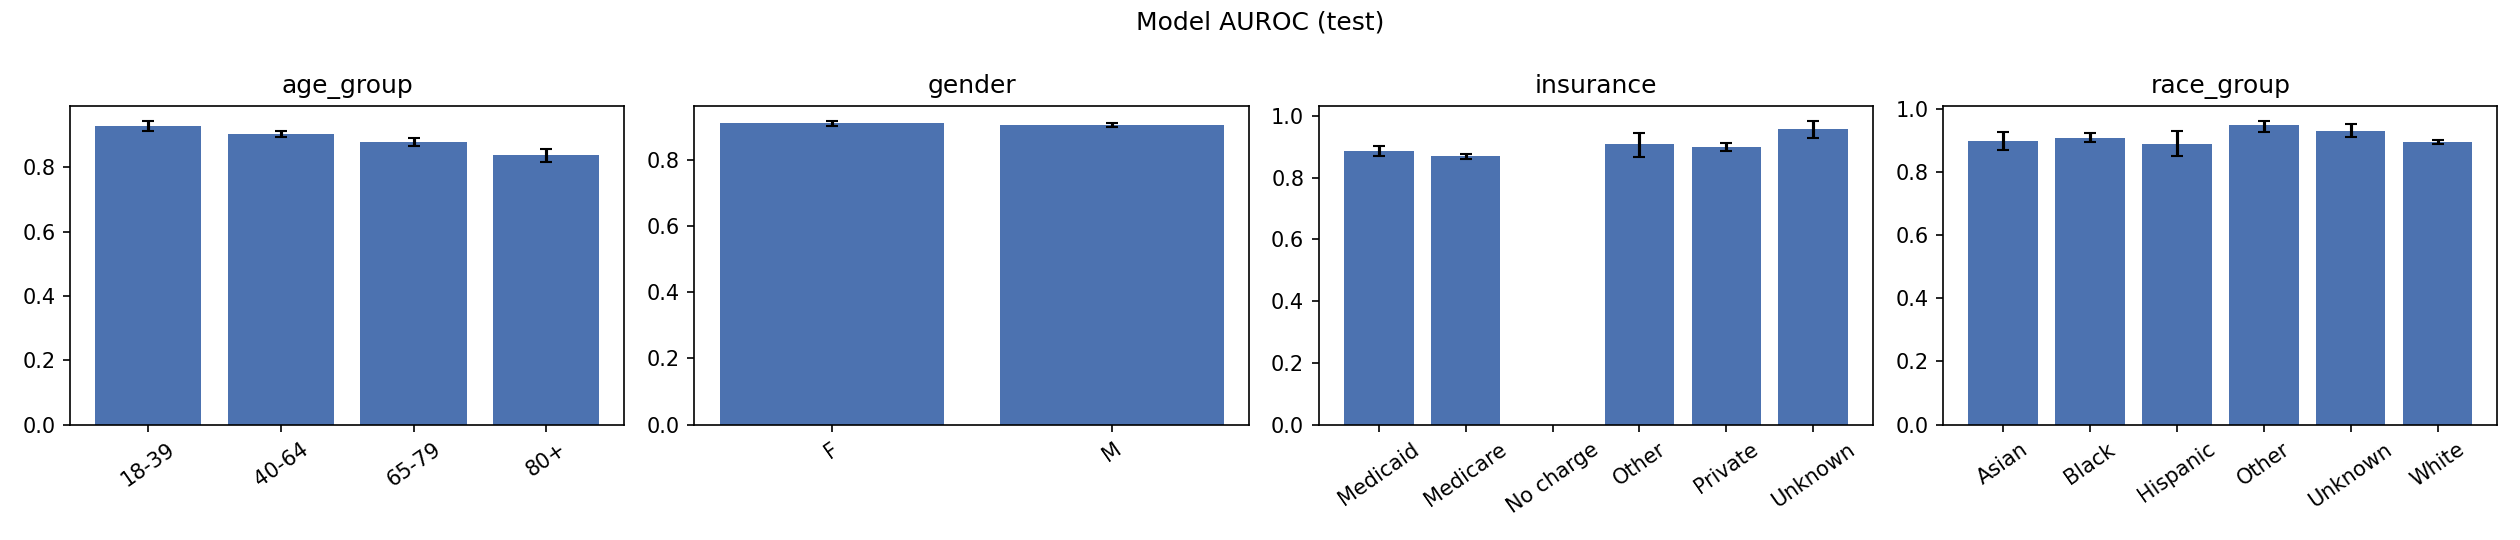

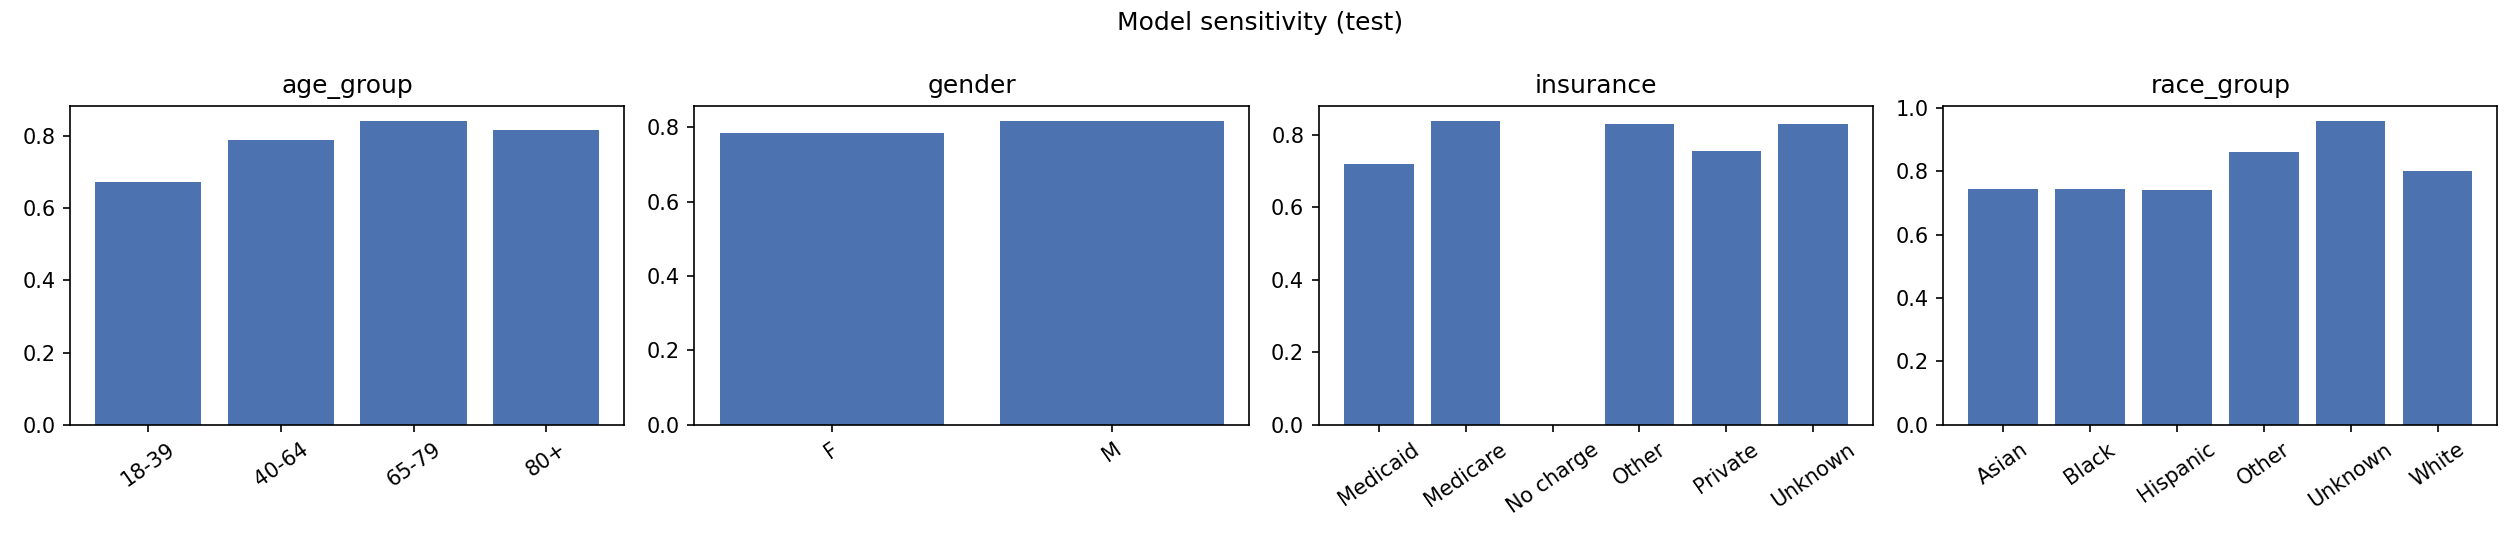

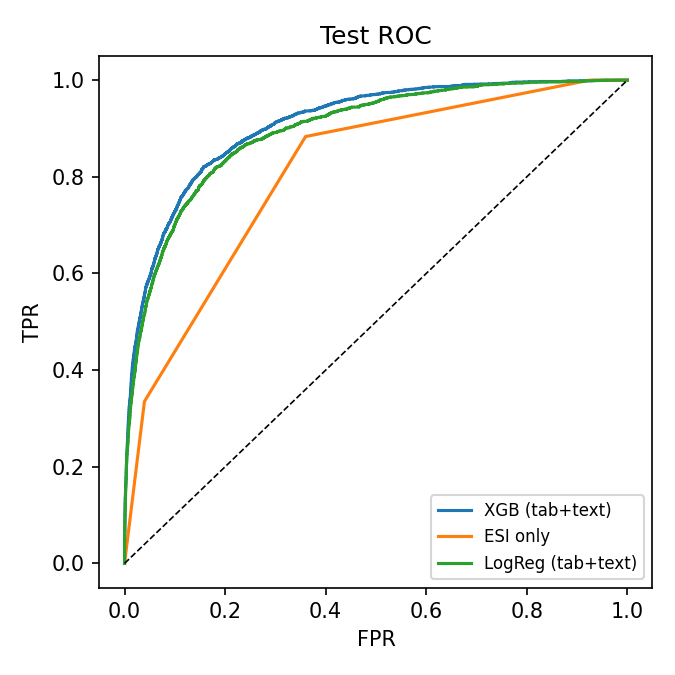

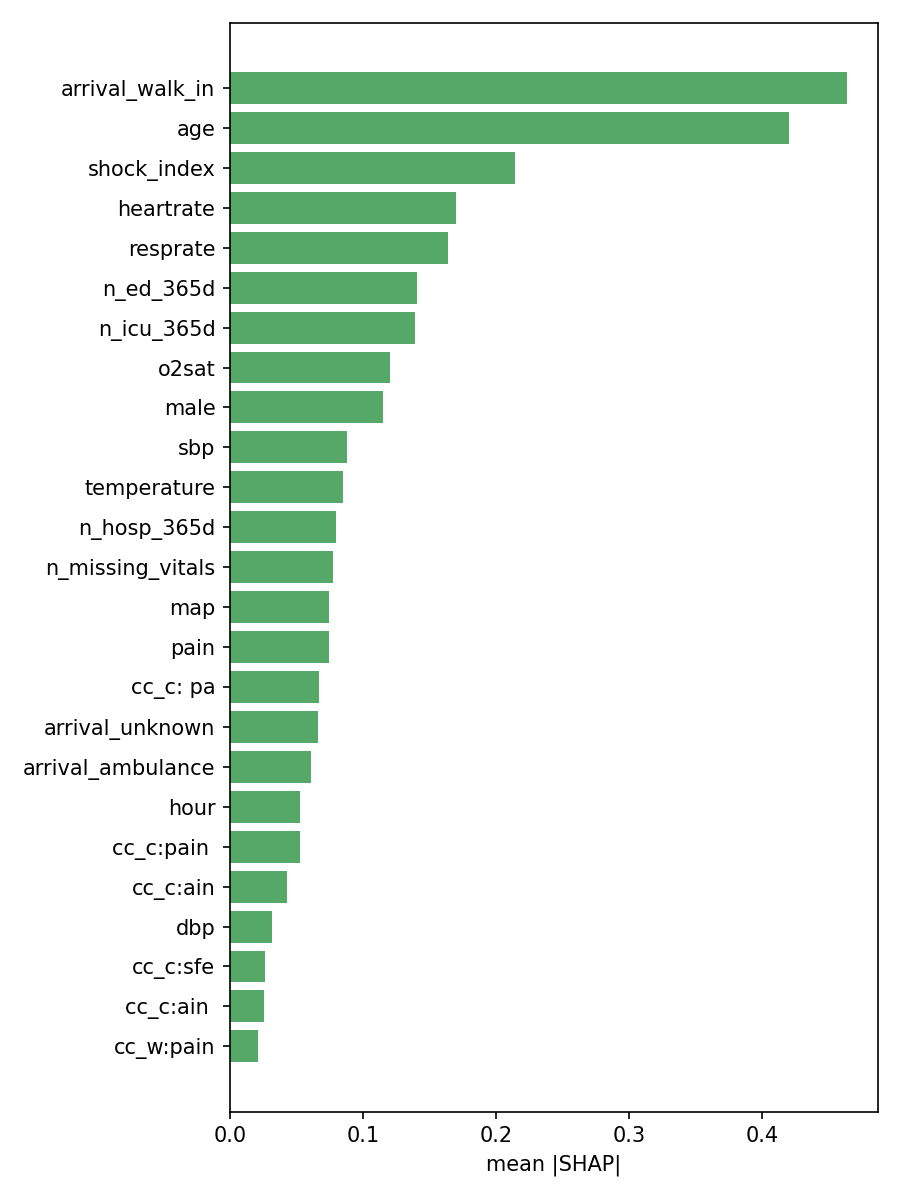

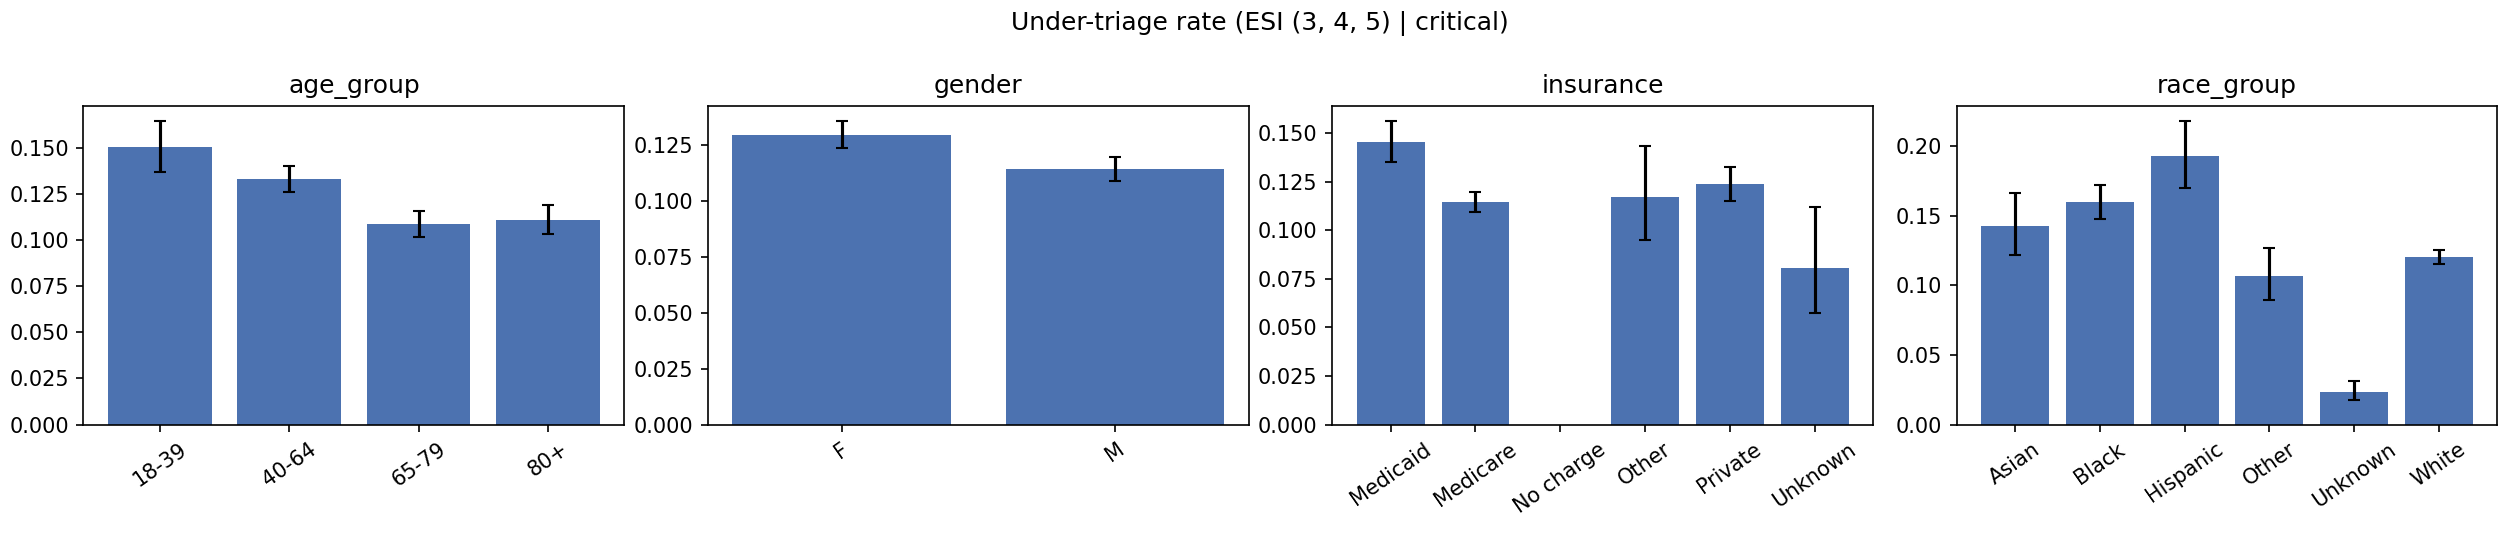

Download /kaggle/working/results_for_github.zip (Output tab) -> unzip into the repo as results/


In [38]:
# Full results report (aggregate only -> safe for GitHub)
import re, shutil, glob
from IPython.display import Markdown, Image, display
rep = f"{cfg.work_dir}/report"
md = open(f"{rep}/REPORT.md", encoding="utf-8").read()
display(Markdown(re.sub(r"!\[.*?\]\(figures/.*?\)", "", md)))
for f in sorted(glob.glob(f"{rep}/figures/*.png")):
    display(Image(f))
shutil.make_archive("/kaggle/working/results_for_github", "zip", rep)
print("Download /kaggle/working/results_for_github.zip (Output tab) -> unzip into the repo as results/")